# Payoff + ETF context · statistics-heavy research notebook

Source model run: **v3.1** · independent ETF long/cash accounts · evaluation ends December 2023.

Each chart contains exactly three curves: **Payoff + context**, **ETF buy & hold**, and **S&P 500 (SPY) buy & hold**. Trading statistics, annual forecasting settings and factors appear underneath. The notebook reads portable saved results; it does not retrain models or retrieve new data.

Capital is normalized to 1 before the first included session open. Costs are 5 bps one way on actual traded notional, including final liquidation. Cash and the Sharpe risk-free convention are zero. The ETF-specific start dates differ. No portfolio is constructed.

In [1]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, HTML
locations = [Path.cwd(), Path.cwd() / 'focused_payoff_context',
             Path.cwd() / 'outputs/swing-tree-local/focused_payoff_context']
ROOT = next((p for p in locations if (p / 'manifest.json').exists()), Path.cwd())
assert (ROOT / 'manifest.json').exists(), 'Open this notebook from its exported folder.'
sys.path.insert(0, str(ROOT / 'src'))
from notebook_views import FocusedReport
R = FocusedReport(ROOT)
display(HTML(R.workflow()))

from statistical_views import StatisticalReport
S = StatisticalReport(ROOT)


## How to read the statistics

A **trade episode** is one continuous spell with positive exposure. Resizing does not start a new episode. Wins, losses and win rates use completed episodes after actual fees; final forced liquidation is identified. Net episode return uses account NAV immediately before entry.

**Forecast horizon** is the selected 5/10/20-session label length. **Holding duration** counts actual invested sessions. Targets are reassessed weekly and positions can persist beyond a label horizon. **Target size while LONG**, **target size across all decisions**, and **daily realized exposure** have different denominators.

Technical, relationship and ETF-context inputs use completed prices. Context factors are market-price proxies, not direct yields, earnings revisions or commodity carry. Macro and FinBERT were excluded from this fitted run because their historical availability was not qualified.

## Research dashboard · all 15 separate accounts

The tables below summarize the current combined procedure. Cross-ETF summaries do not combine capital or create a portfolio. Main equity charts retain exactly the three requested curves.

All derived diagnostics use saved results through 2023. Forecast-target outcomes and weekly account intervals are separate views; neither is a new trading strategy. New benchmark confidence intervals are descriptive after historical inspection.

ETF,Net Sharpe,CAGR,Max drawdown,Volatility,Total return,Daily exposure,Turnover/year
XLK,0.510,7.6%,-33.6%,17.4%,223.0%,66.5%,4.034
XLF,0.336,4.0%,-37.4%,15.1%,87.3%,57.1%,3.052
XLE,0.307,4.2%,-58.1%,20.0%,94.0%,52.4%,6.764
XLV,0.537,6.2%,-20.8%,12.8%,162.9%,62.3%,3.228
XLI,0.466,6.2%,-45.0%,15.4%,159.9%,65.2%,4.086
XLY,0.530,7.6%,-39.7%,16.3%,220.1%,69.9%,1.234
XLP,0.558,6.2%,-24.2%,12.0%,160.0%,75.8%,5.713
XLU,0.284,2.7%,-28.7%,11.8%,52.5%,63.9%,3.280
XLB,0.522,7.0%,-24.7%,15.1%,193.7%,63.3%,6.214
IEF,0.383,2.3%,-23.3%,6.6%,44.3%,85.3%,6.026


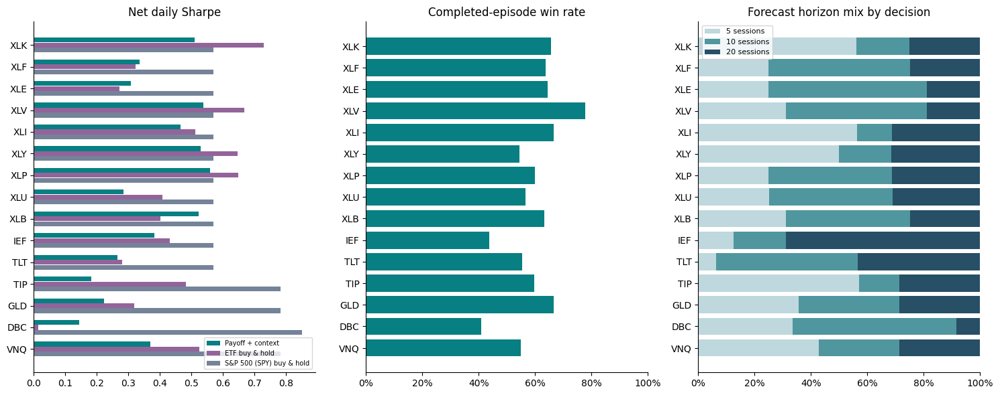

In [2]:
display(HTML(S.overview_tables()))
S.overview_figure()

### Metric definitions and data eligibility

Sharpe uses net simple daily returns and zero risk-free rate. Sortino uses a zero target and the square root of the mean squared negative daily returns across all days. Calmar divides CAGR by the magnitude of maximum drawdown. Tail returns are signed: a more negative 5% tail mean is worse. Annual/monthly returns compound the existing account's saved returns, retaining first-session costs and carry-in positions. Partial periods are identified.

Forecast-label reliability uses only saved outer forecasts with outcomes observable before 2024. The 5/10/20-session labels overlap. Raw classification probabilities, regression returns and calibrated expected payoffs have distinct diagnostics. Fitted prior OOF calibration bins are shown separately from outer forecast evaluation.

Factor importance describes splits in fitted trees and does not establish causality. Model recipe choices, horizons and sizing were chosen on earlier folds; their retrospective stability is descriptive.

In [3]:
display(HTML(S.coverage_tables()))

ticker,first_price_date,last_included_price_date,pre2024_price_rows,duplicate_price_dates,invalid_adjusted_open_close,strategy_start,strategy_end,strategy_sessions,forecast_decisions,available_horizon_outcomes,excluded_trailing_horizon_outcomes
XLK,1998-12-22,2023-12-29,6296,0,0,2008-01-07,2023-12-29,4024,834,833,1
XLF,1998-12-22,2023-12-29,6296,0,0,2008-01-07,2023-12-29,4024,834,832,2
XLE,1998-12-22,2023-12-29,6296,0,0,2008-01-07,2023-12-29,4024,834,833,1
XLV,1998-12-22,2023-12-29,6296,0,0,2008-01-07,2023-12-29,4024,834,833,1
XLI,1998-12-22,2023-12-29,6296,0,0,2008-01-07,2023-12-29,4024,834,830,4
XLY,1998-12-22,2023-12-29,6296,0,0,2008-01-07,2023-12-29,4024,834,833,1
XLP,1998-12-22,2023-12-29,6296,0,0,2008-01-07,2023-12-29,4024,834,833,1
XLU,1998-12-22,2023-12-29,6296,0,0,2008-01-07,2023-12-29,4024,834,830,4
XLB,1998-12-22,2023-12-29,6296,0,0,2008-01-07,2023-12-29,4024,834,833,1
IEF,2002-07-30,2023-12-29,5393,0,0,2008-01-07,2023-12-29,4024,834,832,2


## XLK · equity, trades and model settings

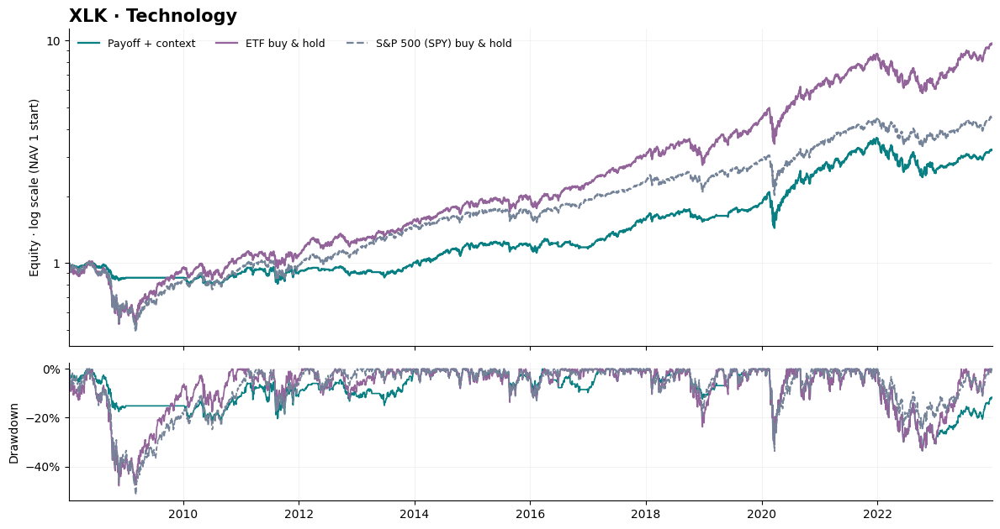

In [4]:
R.plot('XLK')

In [5]:
display(HTML(R.details('XLK')))

### XLK · risk, return distribution and time stability

In [6]:
display(HTML(S.risk_tables('XLK')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,2.230,8.696,3.563
,annualized return,0.076,0.153,0.100
,annualized mean return,0.089,0.169,0.116


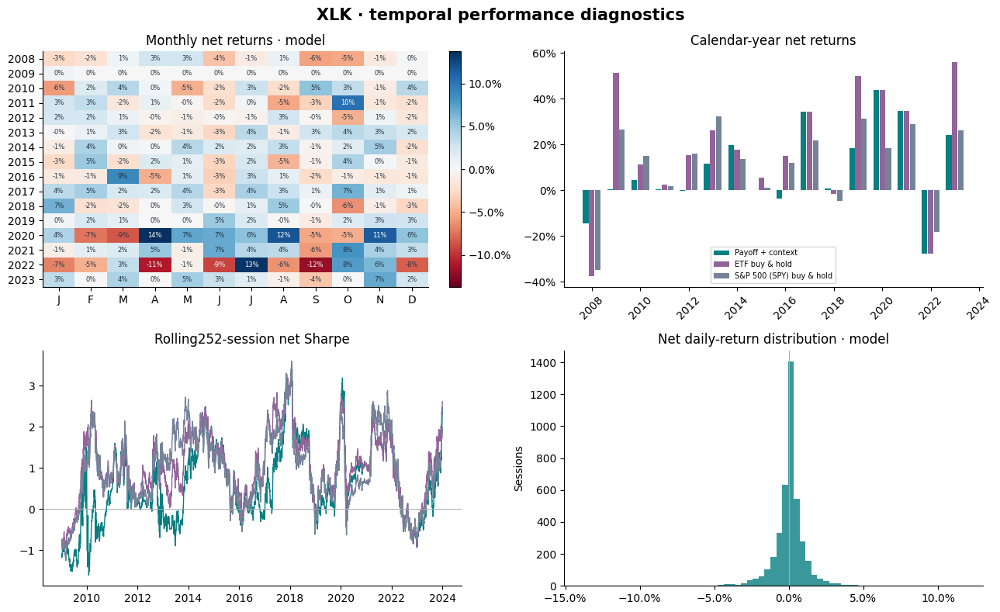

In [7]:
S.temporal_figure('XLK')

In [8]:
display(HTML(S.temporal_tables('XLK')))

### XLK · forecasts, payoff reliability and actual weekly intervals

In [9]:
display(HTML(S.forecast_tables('XLK')))

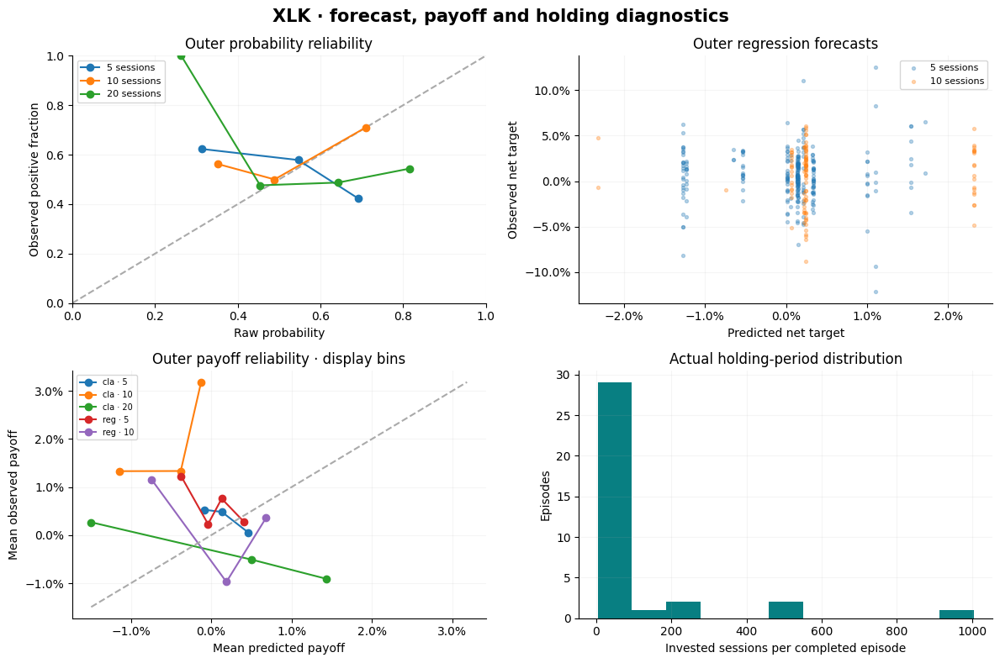

In [10]:
S.forecast_figure('XLK')

### XLK · factors, exposure and benchmark evidence

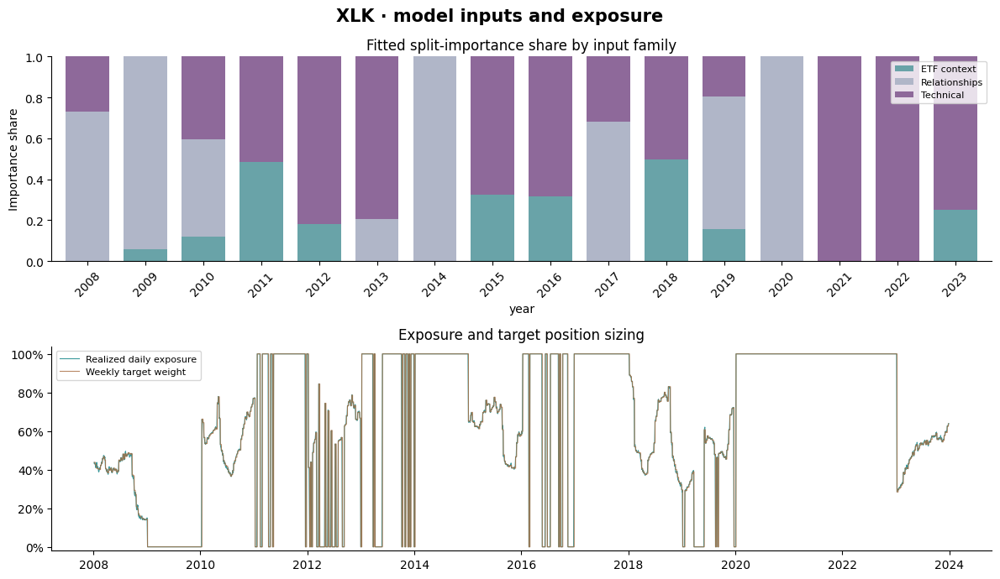

In [11]:
S.factor_figure('XLK')

In [12]:
display(HTML(S.benchmark_tables('XLK')))

## XLF · equity, trades and model settings

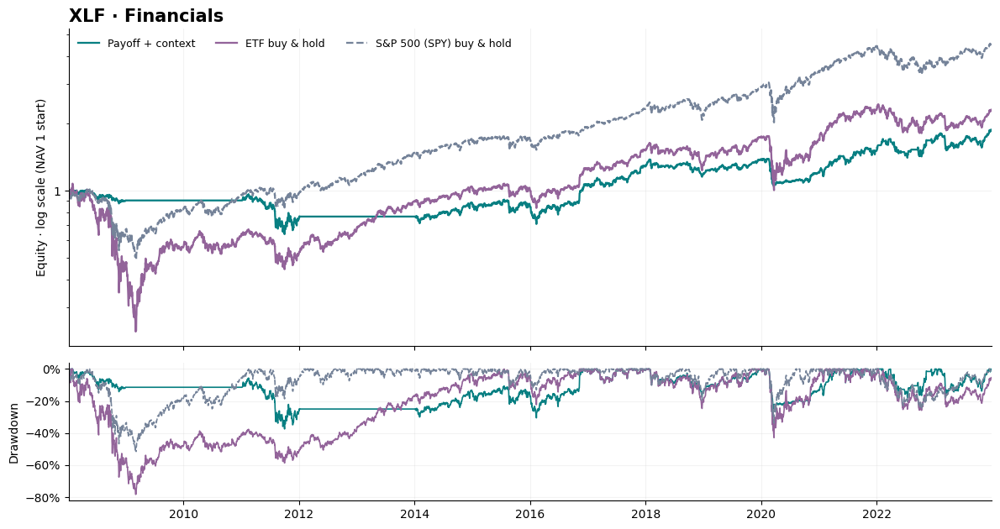

In [13]:
R.plot('XLF')

In [14]:
display(HTML(R.details('XLF')))

### XLF · risk, return distribution and time stability

In [15]:
display(HTML(S.risk_tables('XLF')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,0.873,1.302,3.563
,annualized return,0.040,0.054,0.100
,annualized mean return,0.051,0.104,0.116


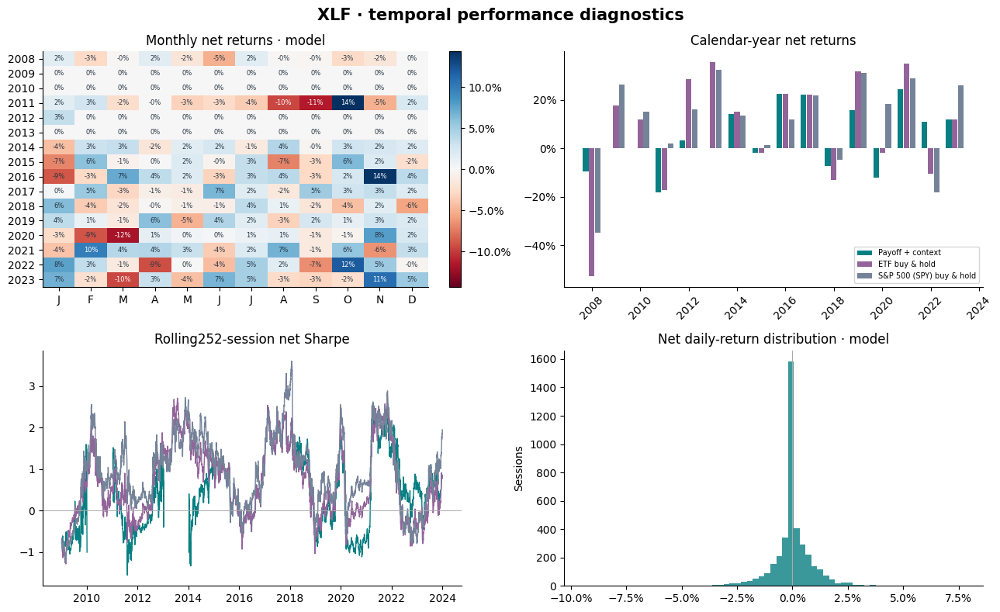

In [16]:
S.temporal_figure('XLF')

In [17]:
display(HTML(S.temporal_tables('XLF')))

### XLF · forecasts, payoff reliability and actual weekly intervals

In [18]:
display(HTML(S.forecast_tables('XLF')))

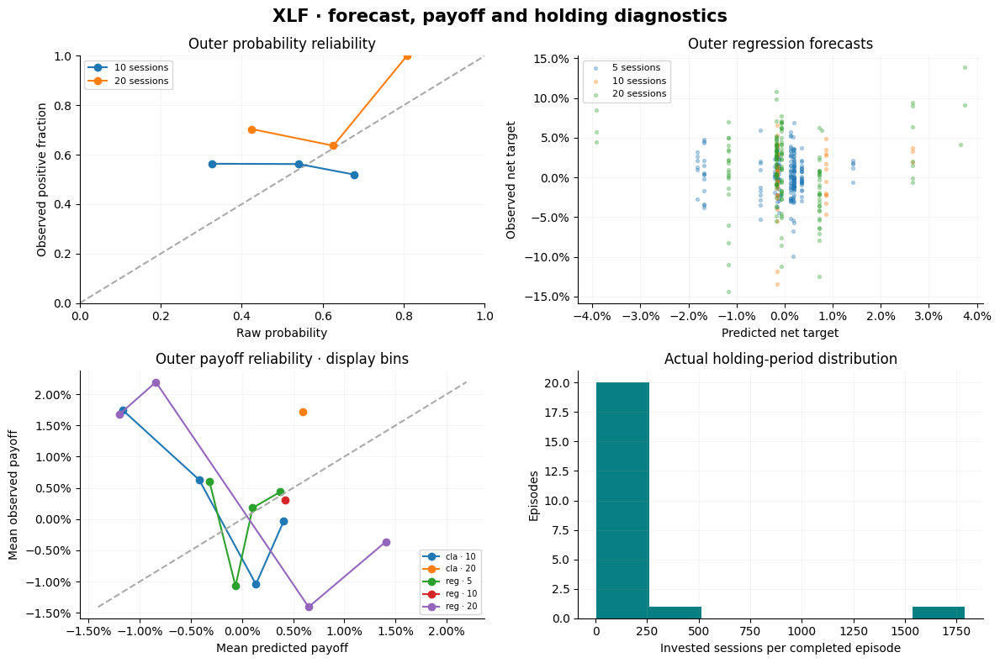

In [19]:
S.forecast_figure('XLF')

### XLF · factors, exposure and benchmark evidence

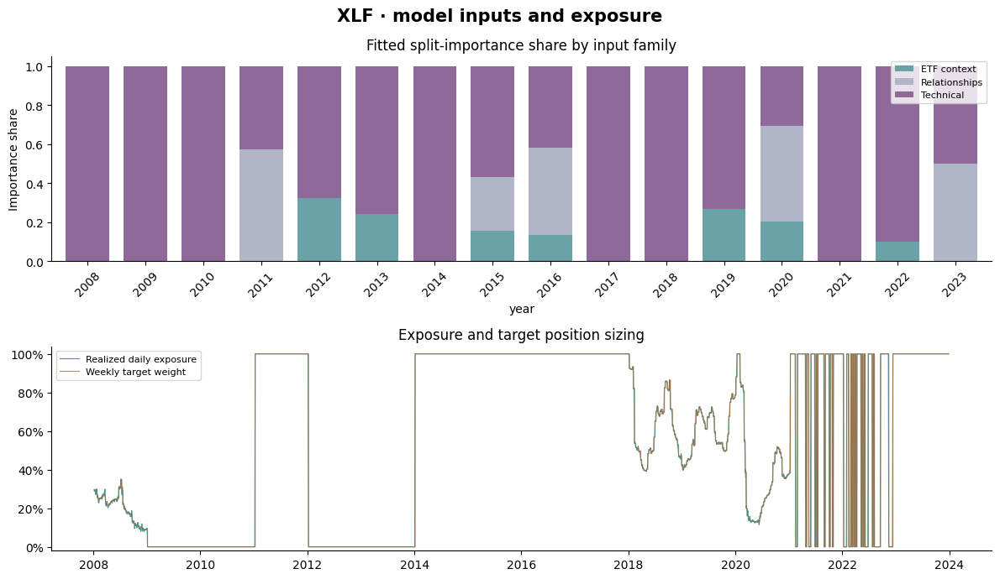

In [20]:
S.factor_figure('XLF')

In [21]:
display(HTML(S.benchmark_tables('XLF')))

## XLE · equity, trades and model settings

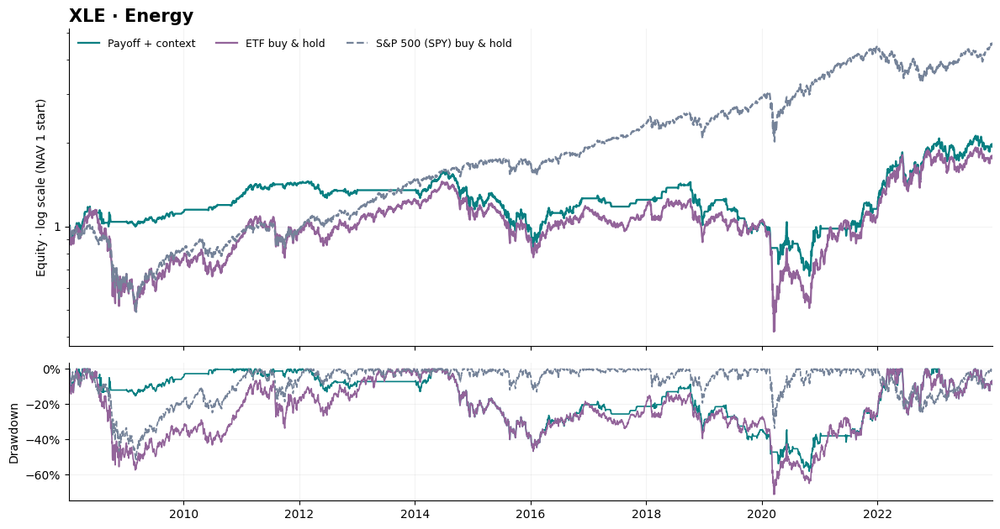

In [22]:
R.plot('XLE')

In [23]:
display(HTML(R.details('XLE')))

### XLE · risk, return distribution and time stability

In [24]:
display(HTML(S.risk_tables('XLE')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,0.940,0.760,3.563
,annualized return,0.042,0.036,0.100
,annualized mean return,0.061,0.086,0.116


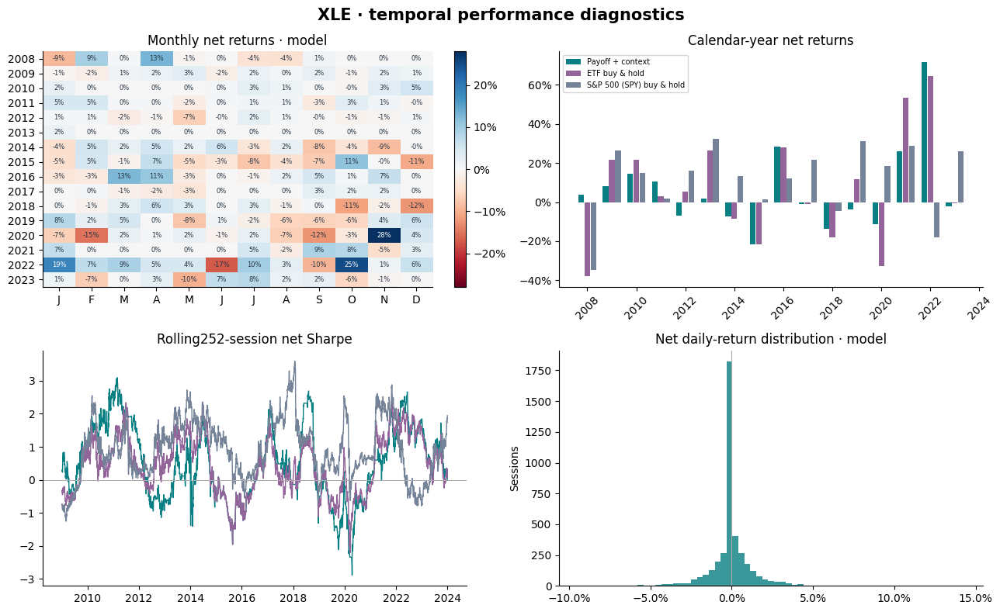

In [25]:
S.temporal_figure('XLE')

In [26]:
display(HTML(S.temporal_tables('XLE')))

### XLE · forecasts, payoff reliability and actual weekly intervals

In [27]:
display(HTML(S.forecast_tables('XLE')))

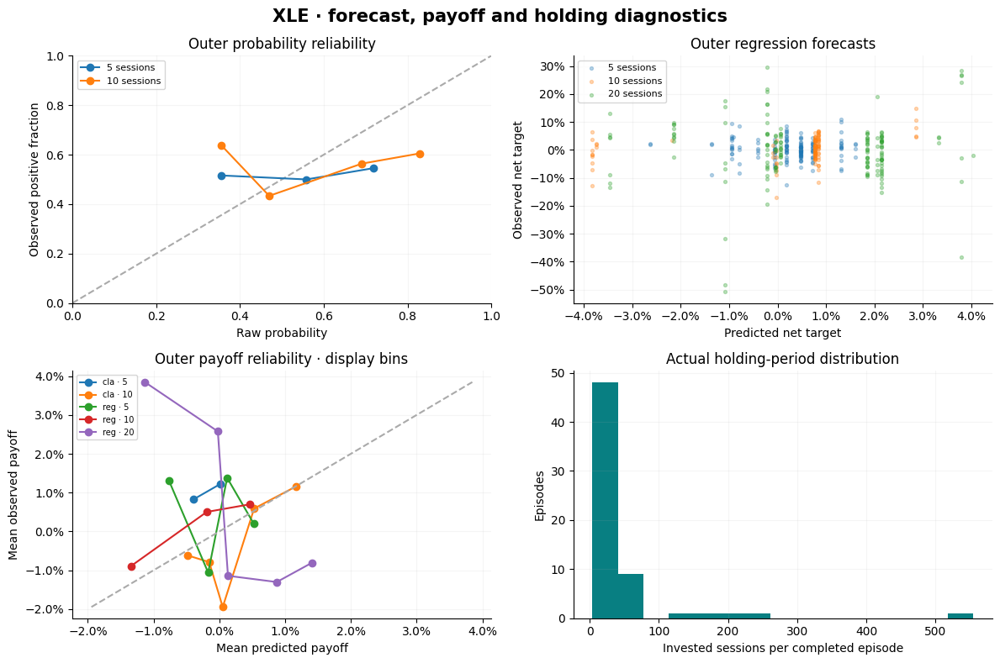

In [28]:
S.forecast_figure('XLE')

### XLE · factors, exposure and benchmark evidence

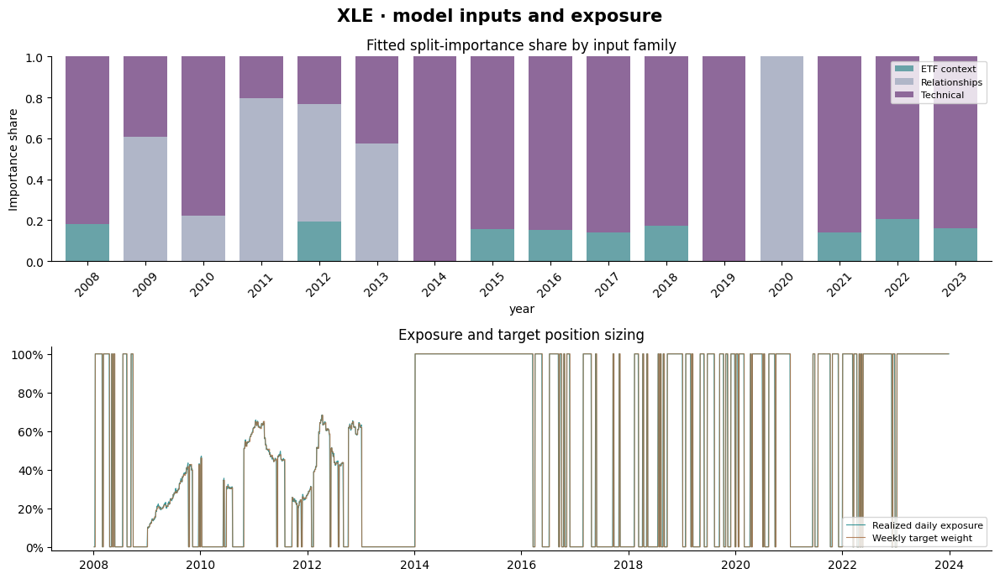

In [29]:
S.factor_figure('XLE')

In [30]:
display(HTML(S.benchmark_tables('XLE')))

## XLV · equity, trades and model settings

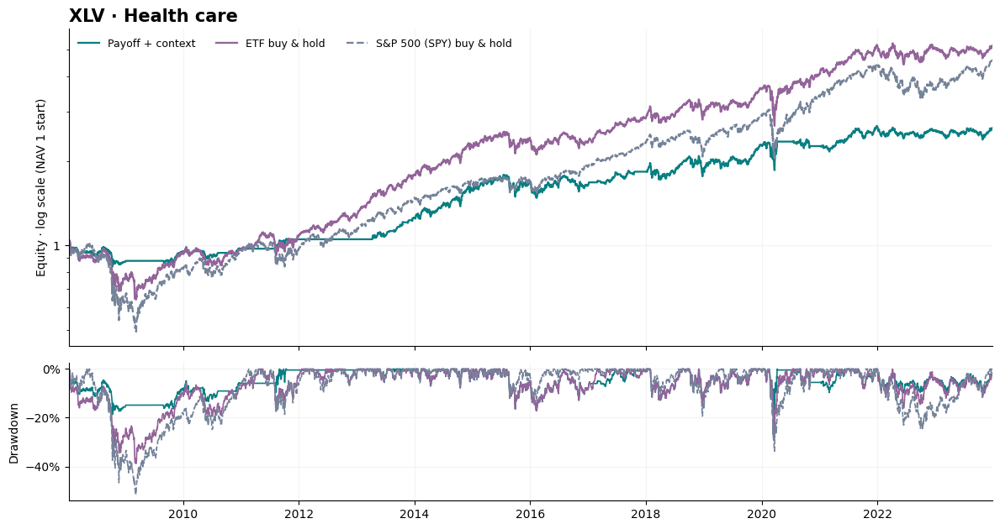

In [31]:
R.plot('XLV')

In [32]:
display(HTML(R.details('XLV')))

### XLV · risk, return distribution and time stability

In [33]:
display(HTML(S.risk_tables('XLV')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,1.629,4.175,3.563
,annualized return,0.062,0.108,0.100
,annualized mean return,0.069,0.119,0.116


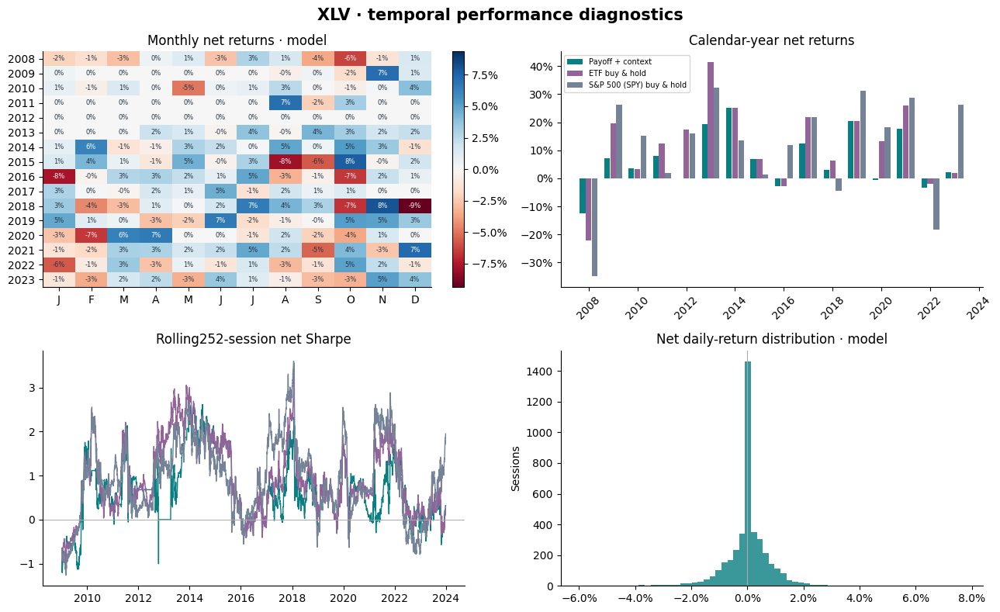

In [34]:
S.temporal_figure('XLV')

In [35]:
display(HTML(S.temporal_tables('XLV')))

### XLV · forecasts, payoff reliability and actual weekly intervals

In [36]:
display(HTML(S.forecast_tables('XLV')))

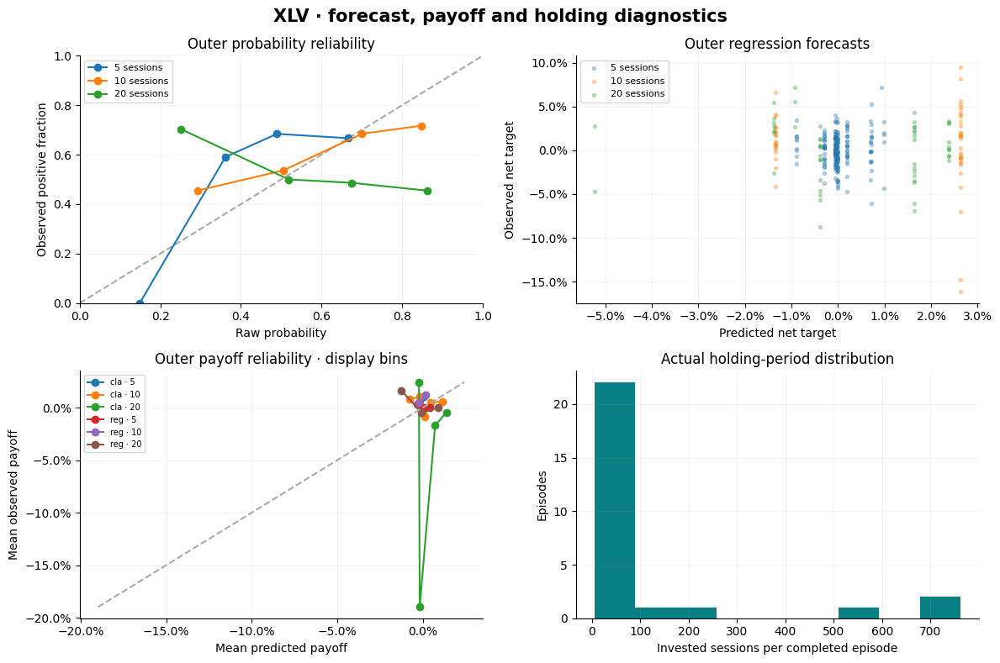

In [37]:
S.forecast_figure('XLV')

### XLV · factors, exposure and benchmark evidence

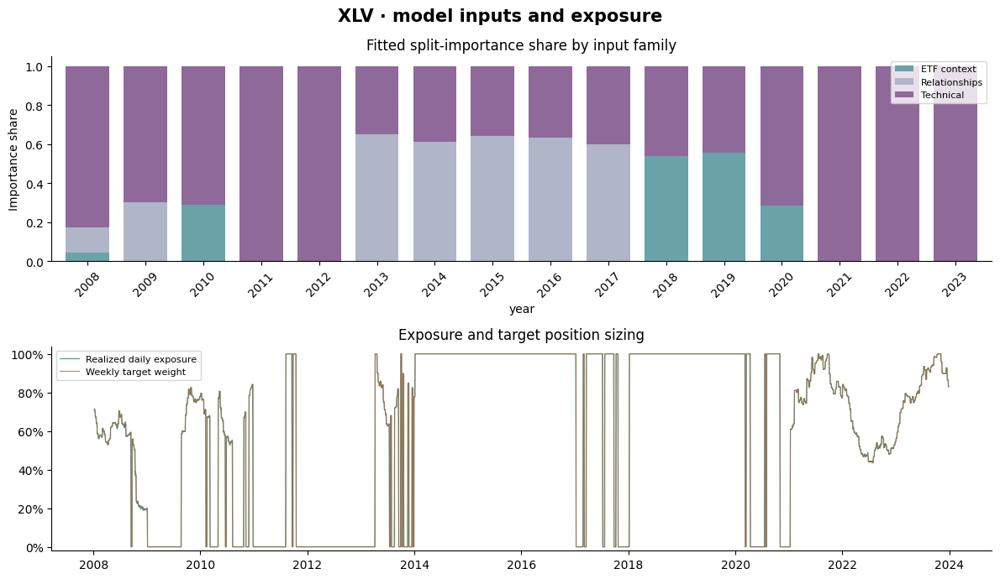

In [38]:
S.factor_figure('XLV')

In [39]:
display(HTML(S.benchmark_tables('XLV')))

## XLI · equity, trades and model settings

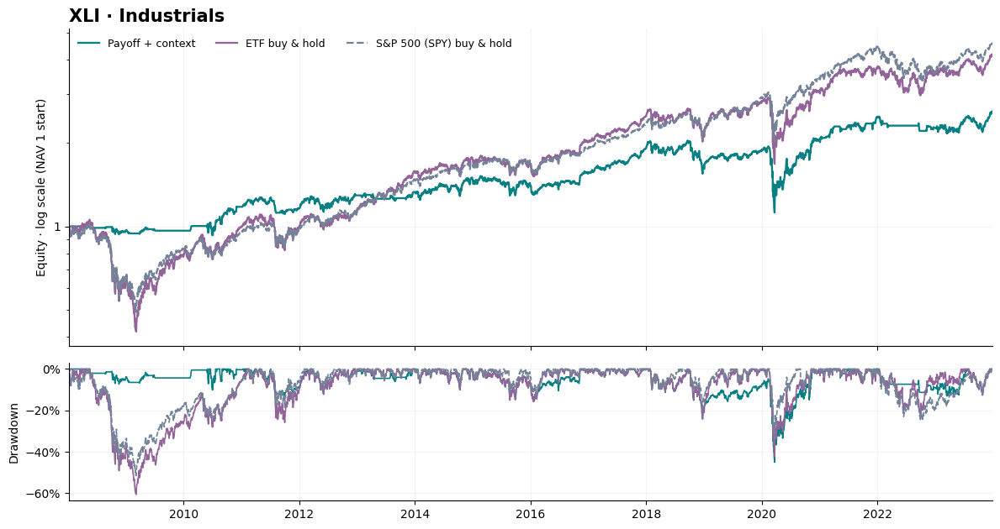

In [40]:
R.plot('XLI')

In [41]:
display(HTML(R.details('XLI')))

### XLI · risk, return distribution and time stability

In [42]:
display(HTML(S.risk_tables('XLI')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,1.599,3.172,3.563
,annualized return,0.062,0.094,0.100
,annualized mean return,0.072,0.115,0.116


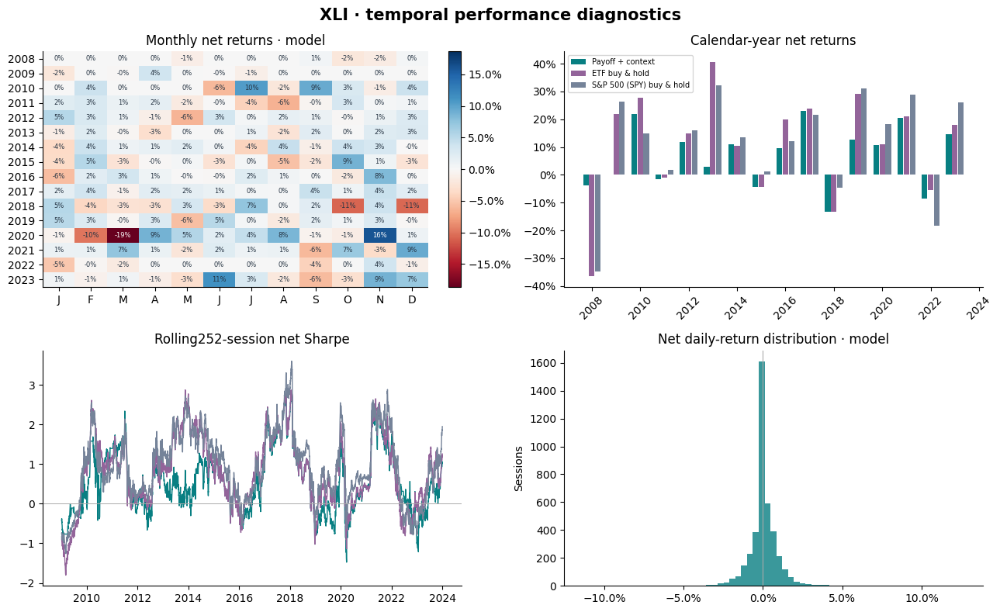

In [43]:
S.temporal_figure('XLI')

In [44]:
display(HTML(S.temporal_tables('XLI')))

### XLI · forecasts, payoff reliability and actual weekly intervals

In [45]:
display(HTML(S.forecast_tables('XLI')))

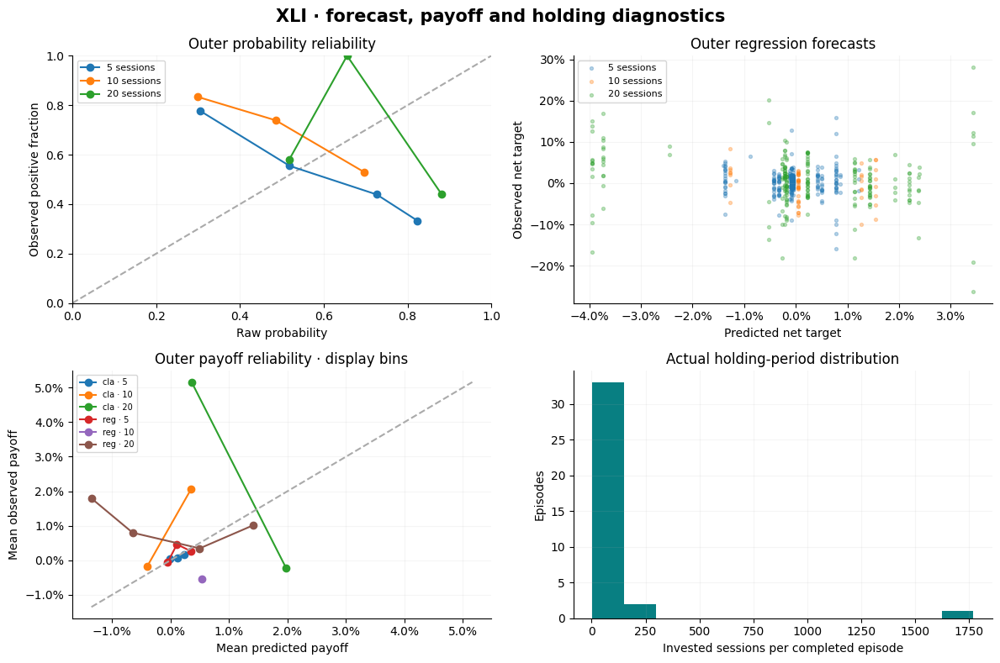

In [46]:
S.forecast_figure('XLI')

### XLI · factors, exposure and benchmark evidence

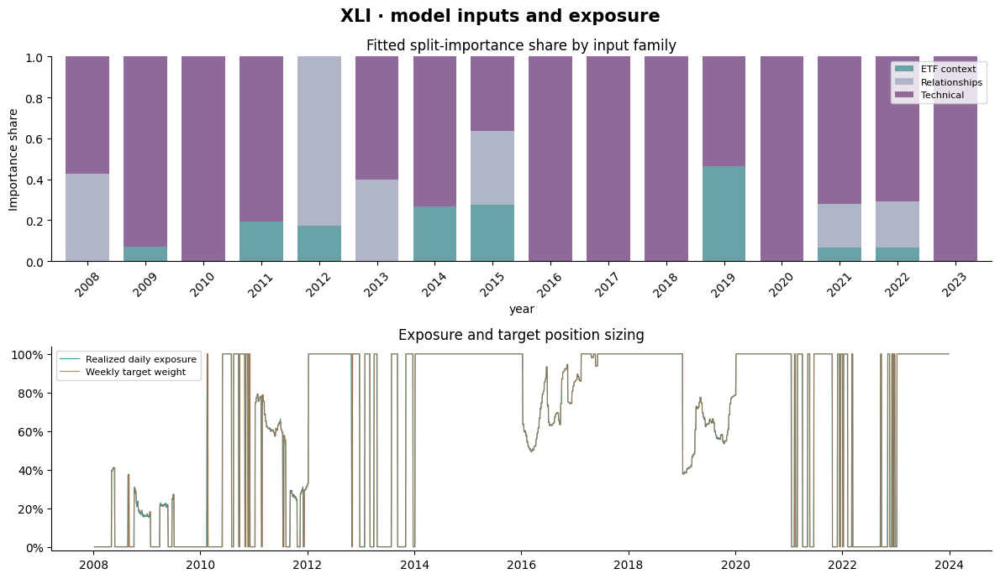

In [47]:
S.factor_figure('XLI')

In [48]:
display(HTML(S.benchmark_tables('XLI')))

## XLY · equity, trades and model settings

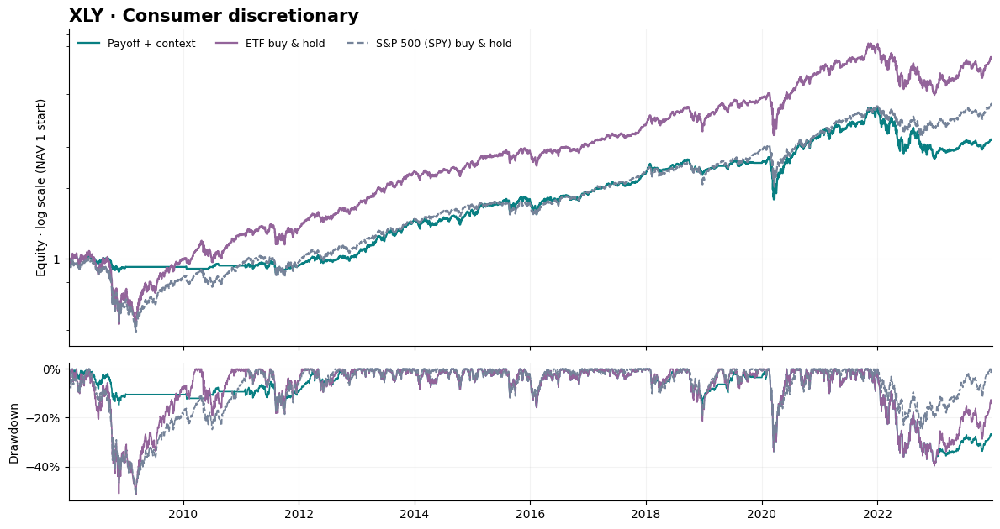

In [49]:
R.plot('XLY')

In [50]:
display(HTML(R.details('XLY')))

### XLY · risk, return distribution and time stability

In [51]:
display(HTML(S.risk_tables('XLY')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,2.201,6.100,3.563
,annualized return,0.076,0.131,0.100
,annualized mean return,0.086,0.150,0.116


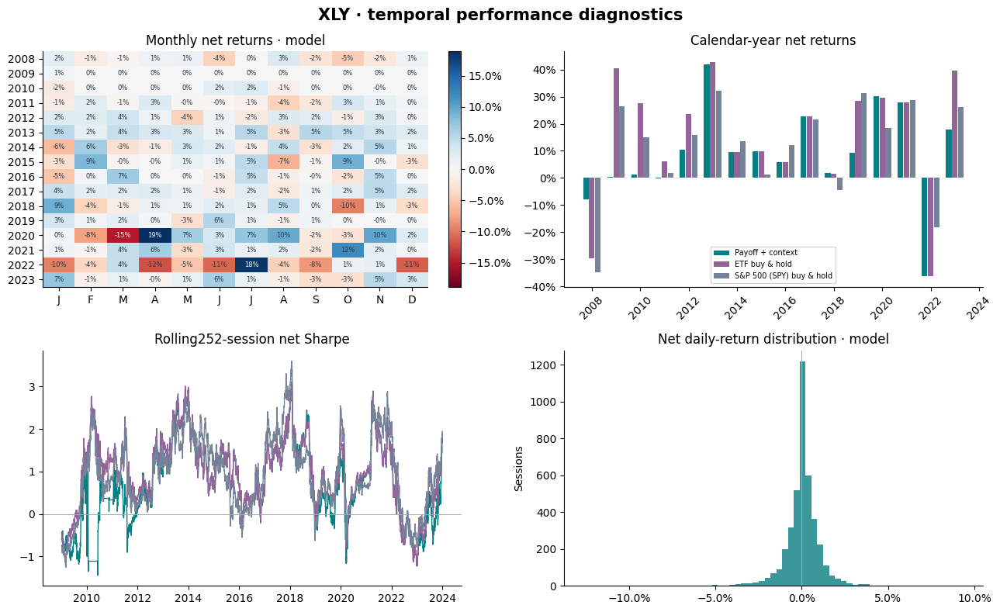

In [52]:
S.temporal_figure('XLY')

In [53]:
display(HTML(S.temporal_tables('XLY')))

### XLY · forecasts, payoff reliability and actual weekly intervals

In [54]:
display(HTML(S.forecast_tables('XLY')))

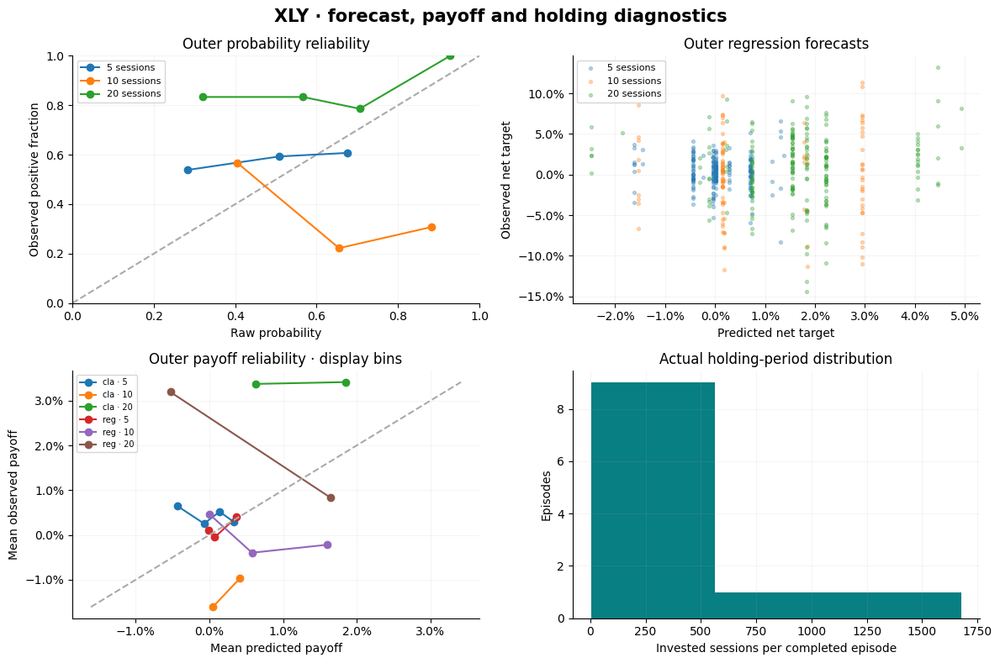

In [55]:
S.forecast_figure('XLY')

### XLY · factors, exposure and benchmark evidence

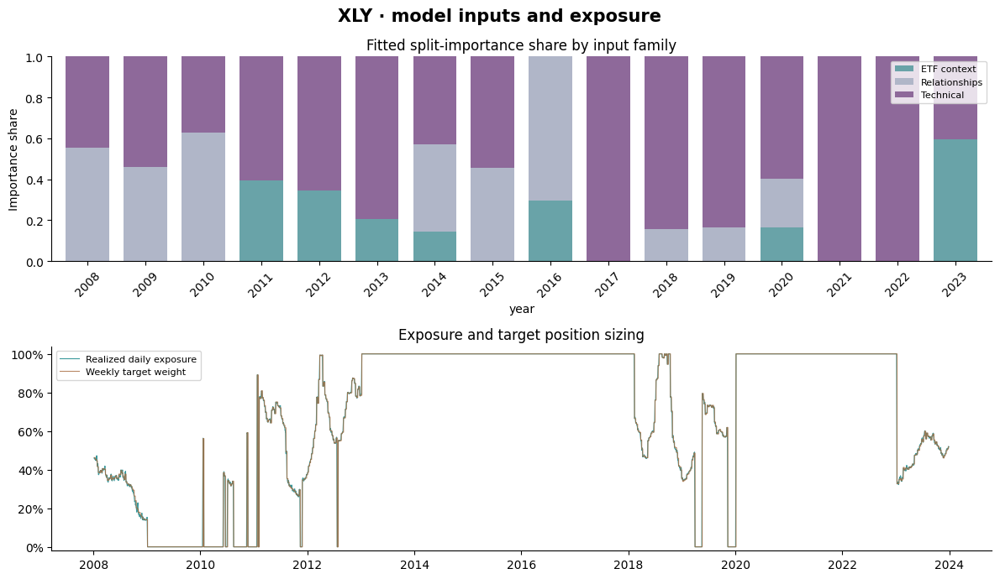

In [56]:
S.factor_figure('XLY')

In [57]:
display(HTML(S.benchmark_tables('XLY')))

## XLP · equity, trades and model settings

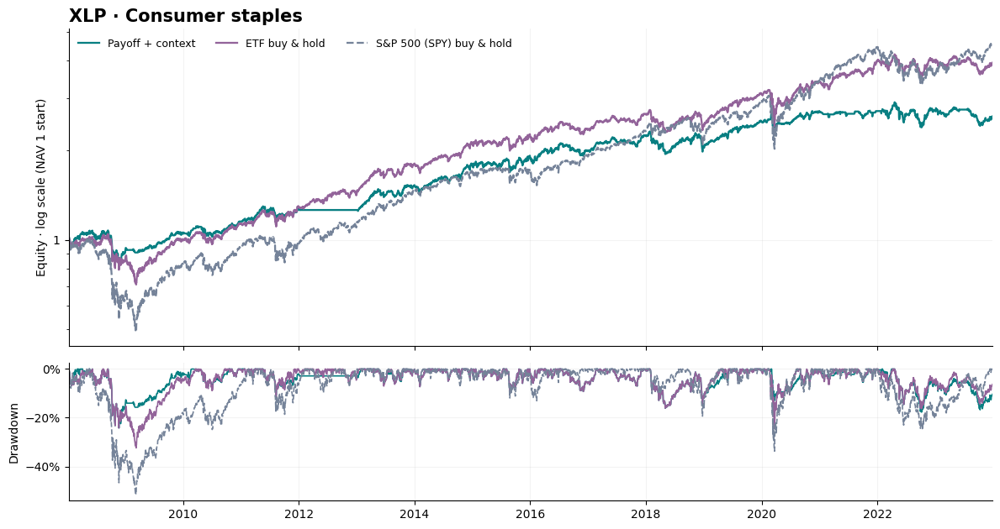

In [58]:
R.plot('XLP')

In [59]:
display(HTML(R.details('XLP')))

### XLP · risk, return distribution and time stability

In [60]:
display(HTML(S.risk_tables('XLP')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,1.600,2.938,3.563
,annualized return,0.062,0.090,0.100
,annualized mean return,0.067,0.097,0.116


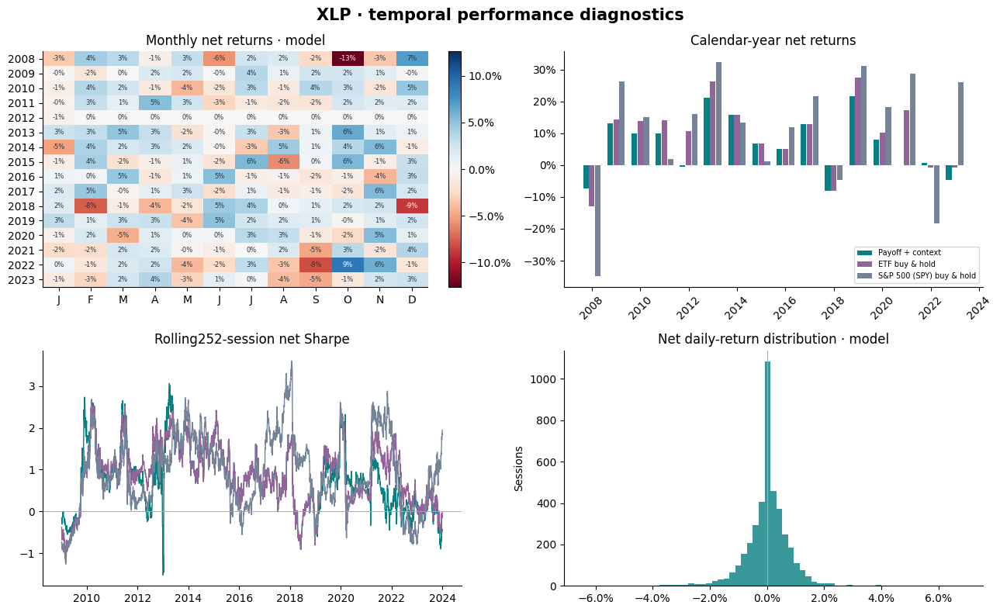

In [61]:
S.temporal_figure('XLP')

In [62]:
display(HTML(S.temporal_tables('XLP')))

### XLP · forecasts, payoff reliability and actual weekly intervals

In [63]:
display(HTML(S.forecast_tables('XLP')))

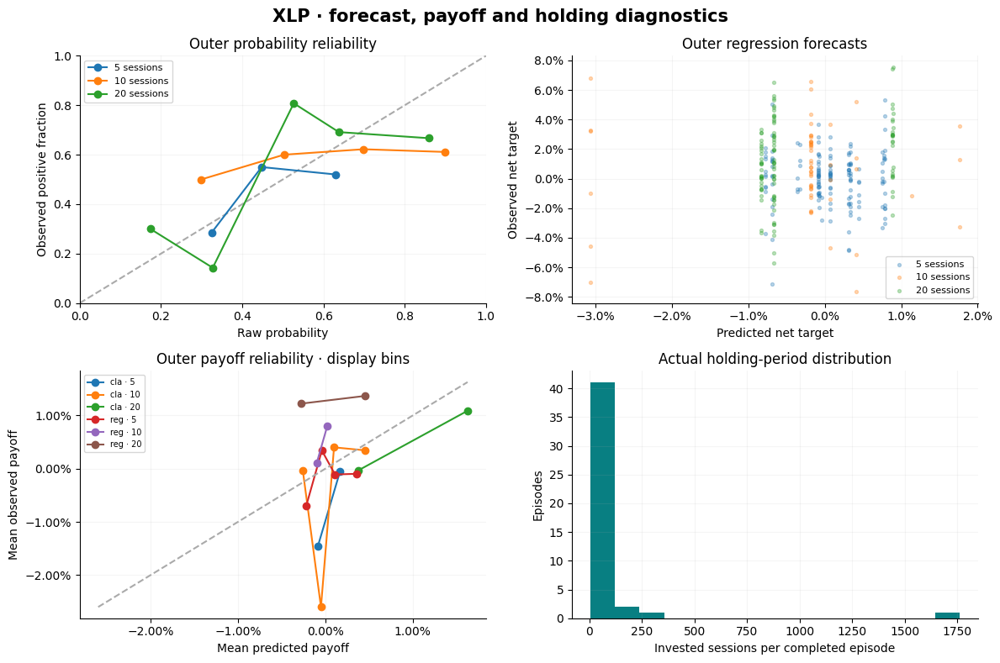

In [64]:
S.forecast_figure('XLP')

### XLP · factors, exposure and benchmark evidence

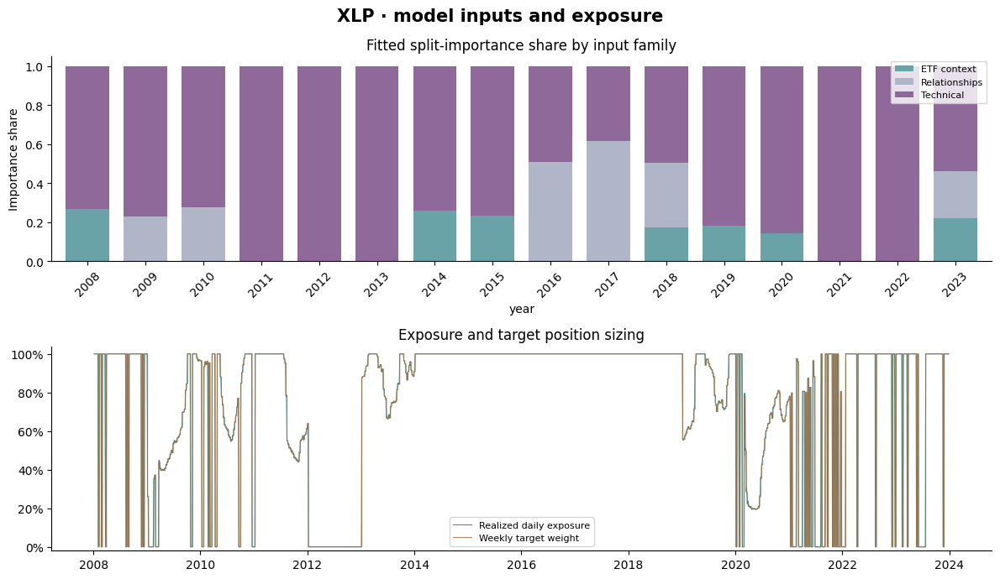

In [65]:
S.factor_figure('XLP')

In [66]:
display(HTML(S.benchmark_tables('XLP')))

## XLU · equity, trades and model settings

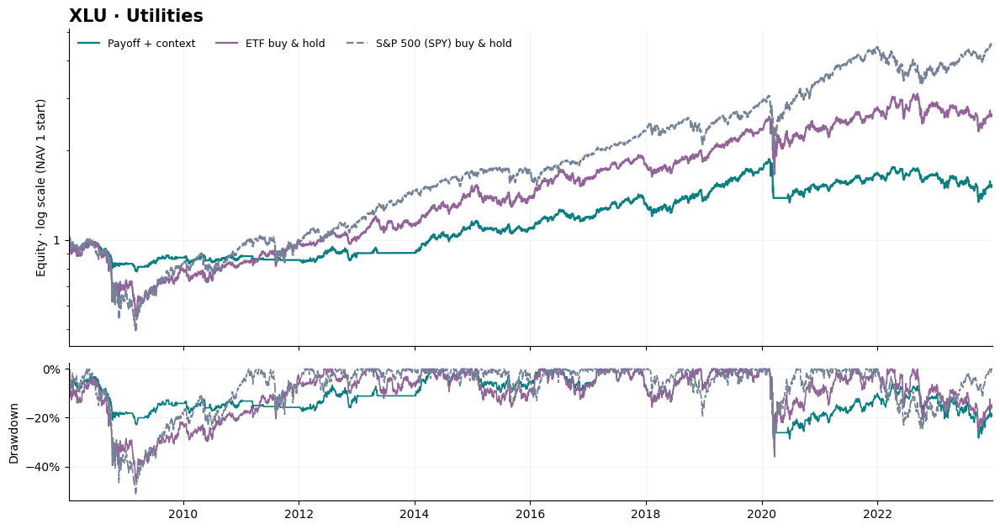

In [67]:
R.plot('XLU')

In [68]:
display(HTML(R.details('XLU')))

### XLU · risk, return distribution and time stability

In [69]:
display(HTML(S.risk_tables('XLU')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,0.525,1.634,3.563
,annualized return,0.027,0.063,0.100
,annualized mean return,0.033,0.080,0.116


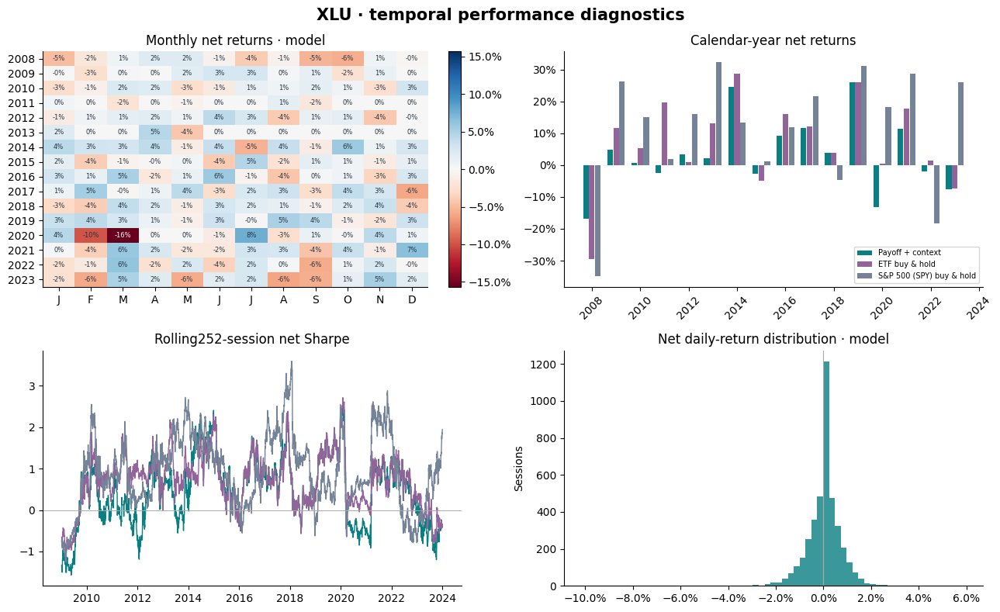

In [70]:
S.temporal_figure('XLU')

In [71]:
display(HTML(S.temporal_tables('XLU')))

### XLU · forecasts, payoff reliability and actual weekly intervals

In [72]:
display(HTML(S.forecast_tables('XLU')))

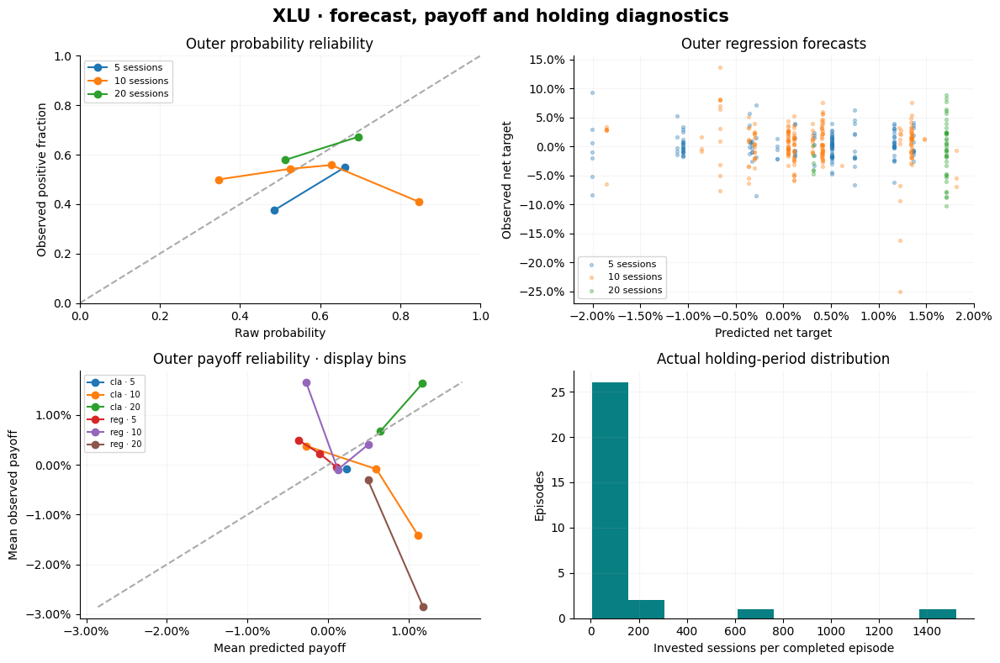

In [73]:
S.forecast_figure('XLU')

### XLU · factors, exposure and benchmark evidence

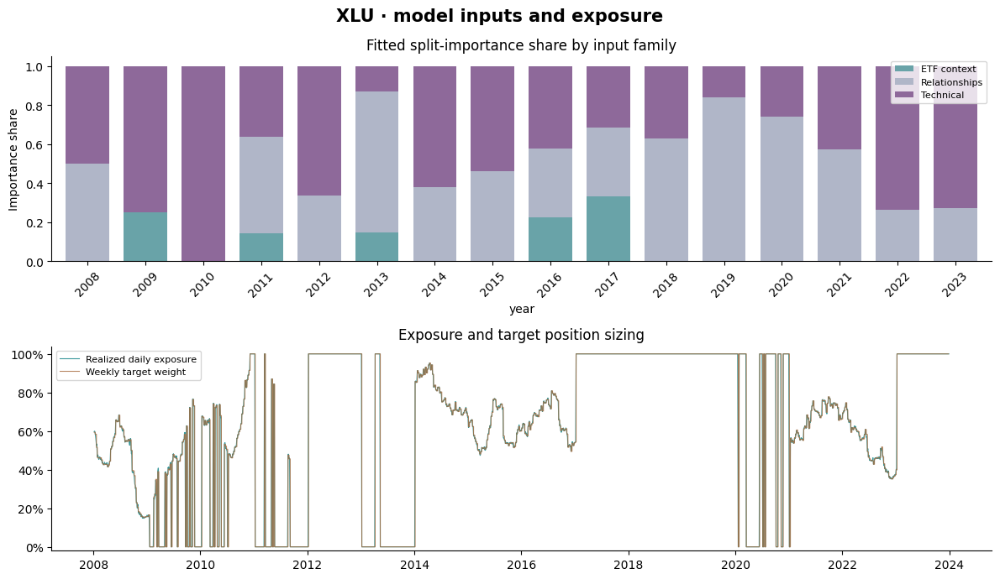

In [74]:
S.factor_figure('XLU')

In [75]:
display(HTML(S.benchmark_tables('XLU')))

## XLB · equity, trades and model settings

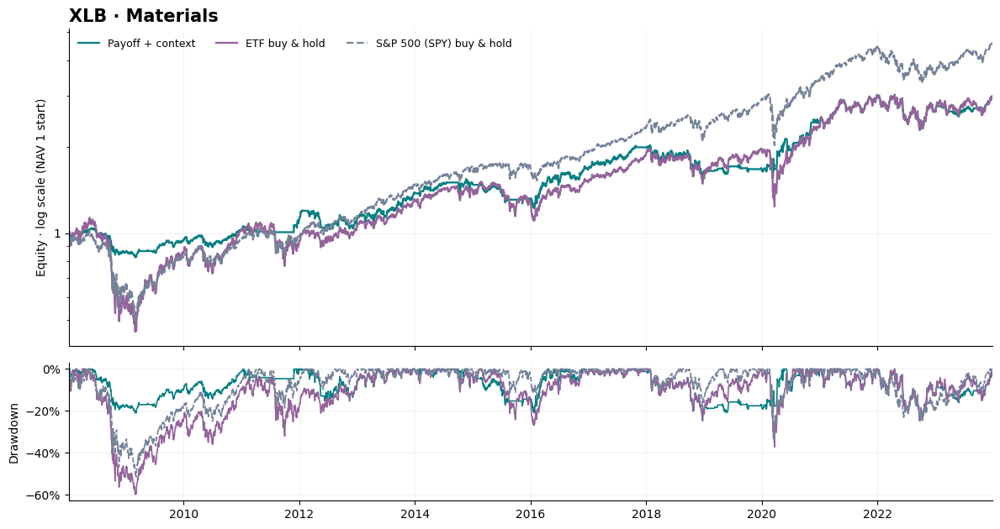

In [76]:
R.plot('XLB')

In [77]:
display(HTML(R.details('XLB')))

### XLB · risk, return distribution and time stability

In [78]:
display(HTML(S.risk_tables('XLB')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,1.937,1.978,3.563
,annualized return,0.070,0.071,0.100
,annualized mean return,0.079,0.099,0.116


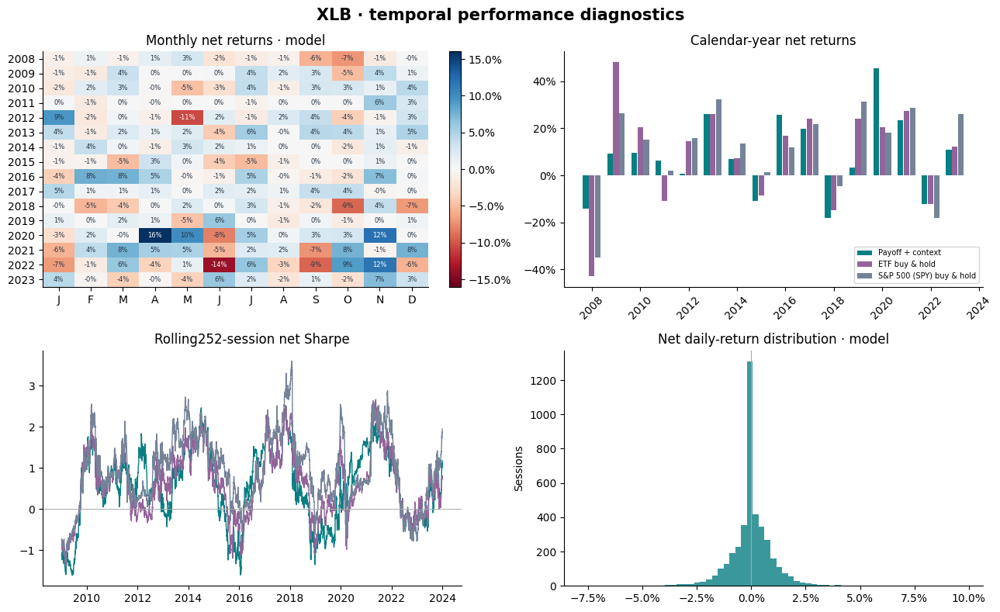

In [79]:
S.temporal_figure('XLB')

In [80]:
display(HTML(S.temporal_tables('XLB')))

### XLB · forecasts, payoff reliability and actual weekly intervals

In [81]:
display(HTML(S.forecast_tables('XLB')))

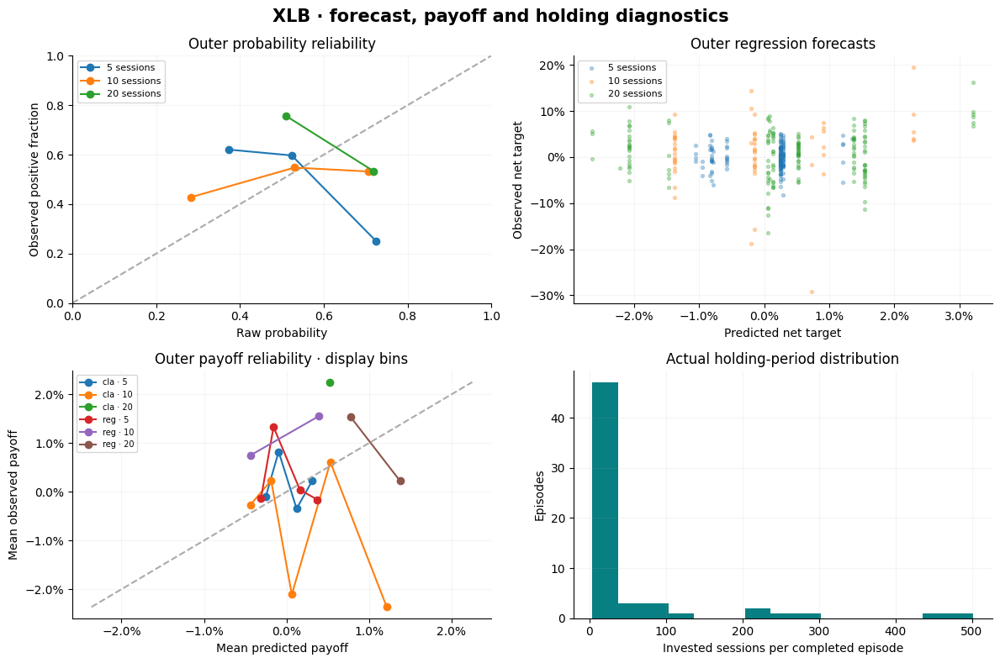

In [82]:
S.forecast_figure('XLB')

### XLB · factors, exposure and benchmark evidence

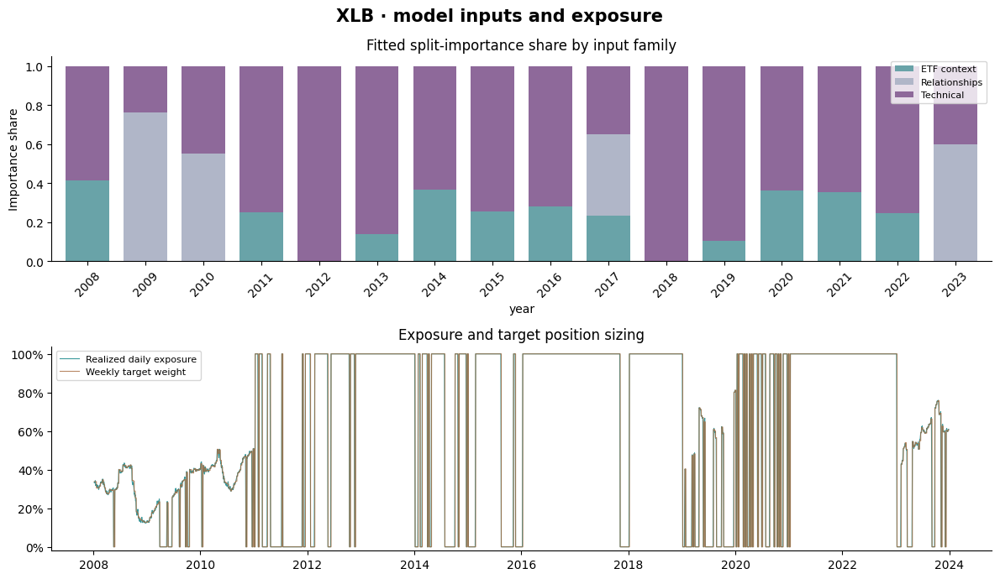

In [83]:
S.factor_figure('XLB')

In [84]:
display(HTML(S.benchmark_tables('XLB')))

## IEF · equity, trades and model settings

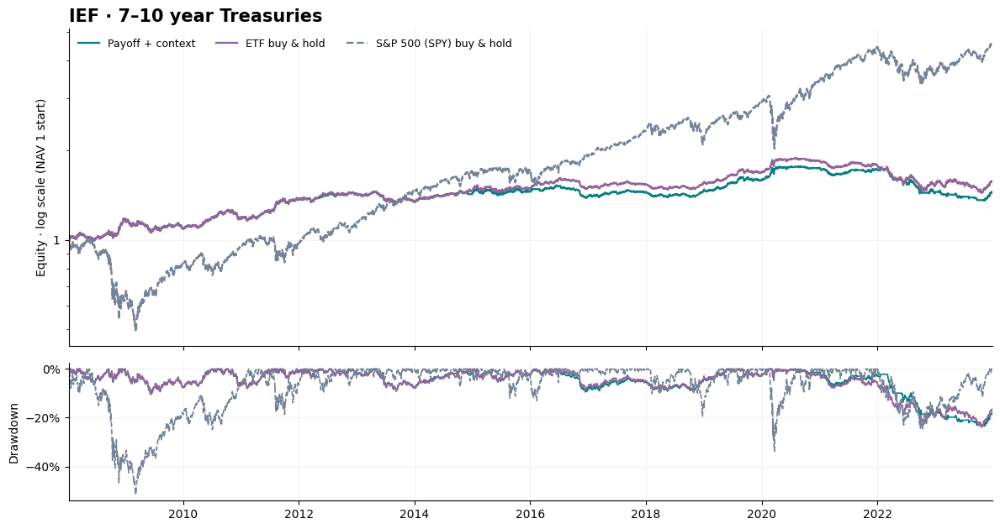

In [85]:
R.plot('IEF')

In [86]:
display(HTML(R.details('IEF')))

### IEF · risk, return distribution and time stability

In [87]:
display(HTML(S.risk_tables('IEF')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,0.443,0.570,3.563
,annualized return,0.023,0.029,0.100
,annualized mean return,0.025,0.031,0.116


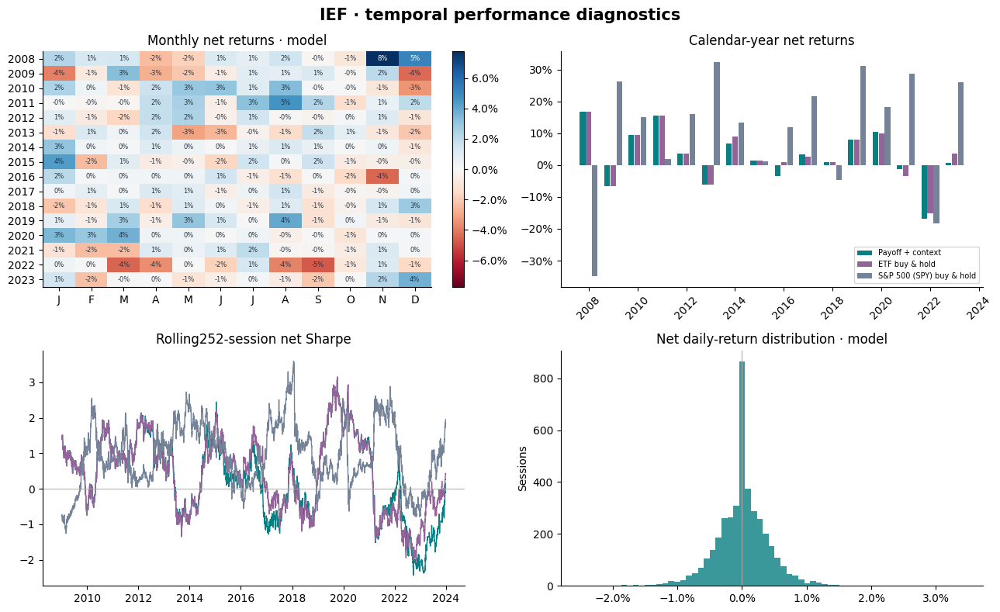

In [88]:
S.temporal_figure('IEF')

In [89]:
display(HTML(S.temporal_tables('IEF')))

### IEF · forecasts, payoff reliability and actual weekly intervals

In [90]:
display(HTML(S.forecast_tables('IEF')))

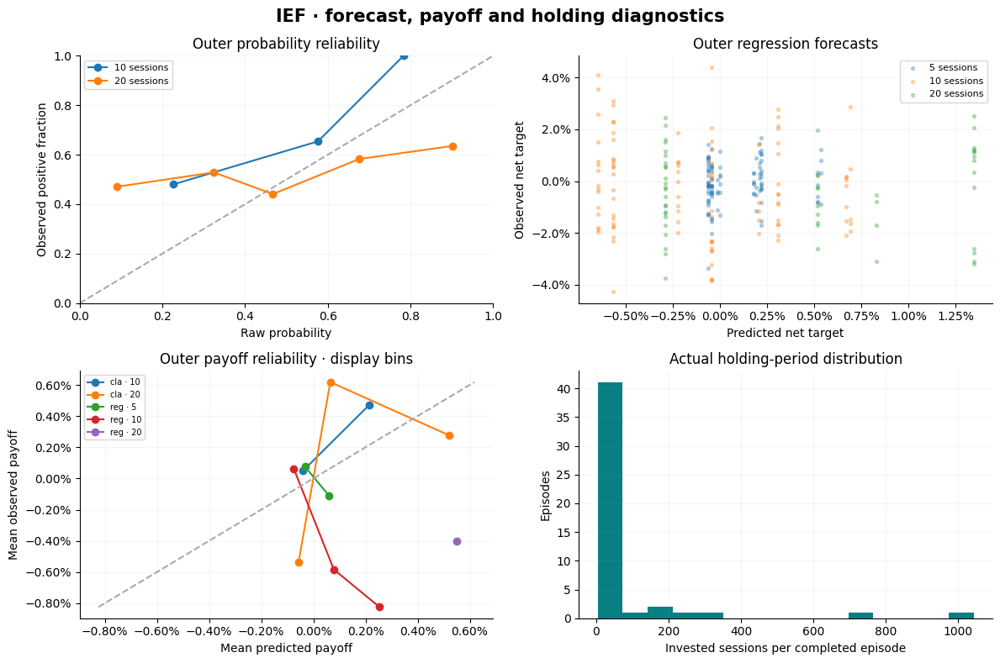

In [91]:
S.forecast_figure('IEF')

### IEF · factors, exposure and benchmark evidence

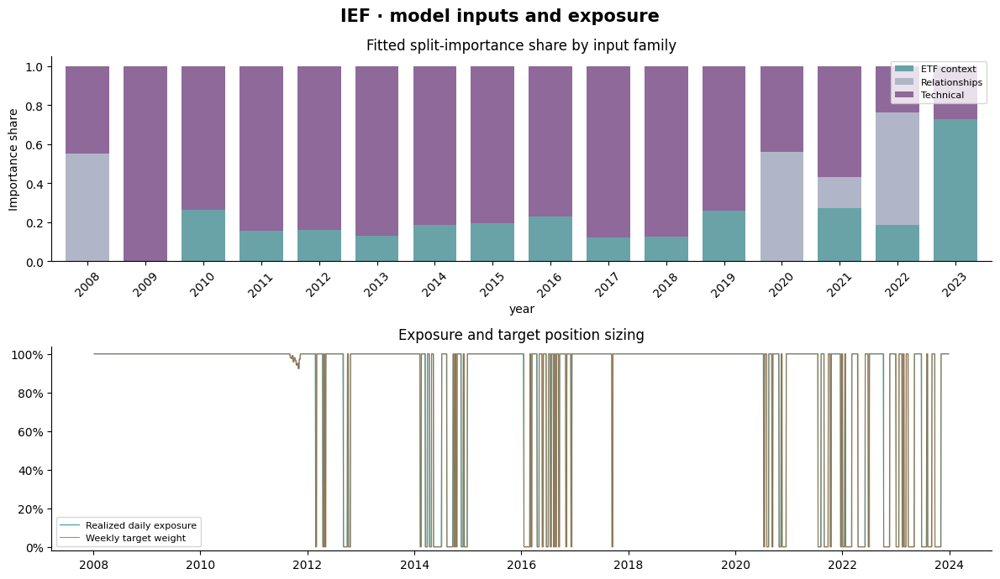

In [92]:
S.factor_figure('IEF')

In [93]:
display(HTML(S.benchmark_tables('IEF')))

## TLT · equity, trades and model settings

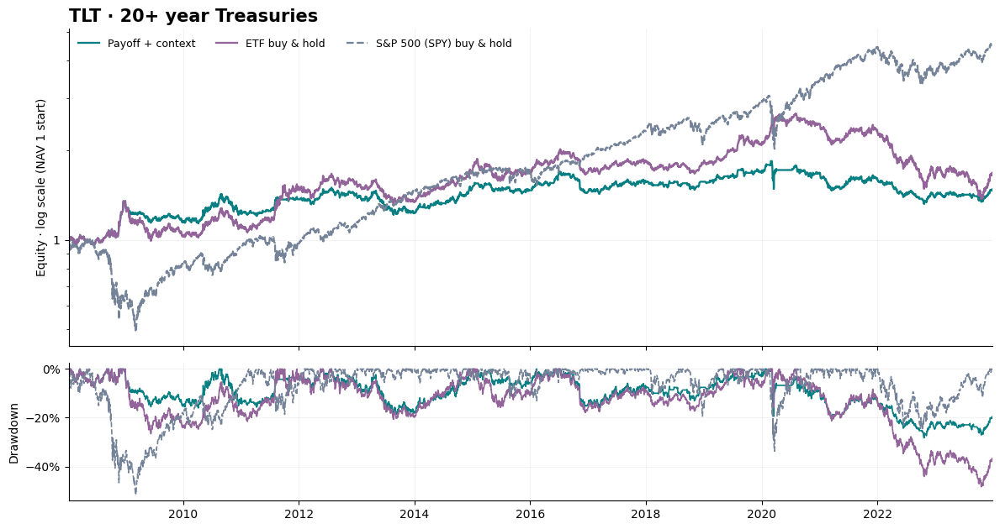

In [94]:
R.plot('TLT')

In [95]:
display(HTML(R.details('TLT')))

### TLT · risk, return distribution and time stability

In [96]:
display(HTML(S.risk_tables('TLT')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2008-01-07,2008-01-07,2008-01-07
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,4024,4024,4024
,days,4024,4024,4024
,calendar days,5836,5836,5836
,elapsed calendar days,5835,5835,5835
,annualization years 252,15.968,15.968,15.968
,net return,0.469,0.654,3.563
,annualized return,0.024,0.032,0.100
,annualized mean return,0.031,0.044,0.116


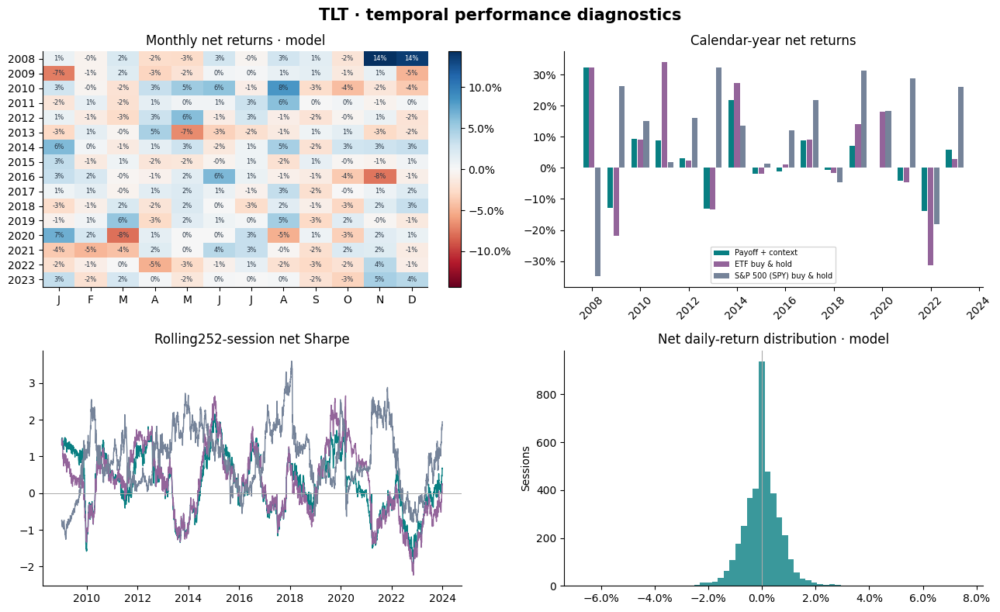

In [97]:
S.temporal_figure('TLT')

In [98]:
display(HTML(S.temporal_tables('TLT')))

### TLT · forecasts, payoff reliability and actual weekly intervals

In [99]:
display(HTML(S.forecast_tables('TLT')))

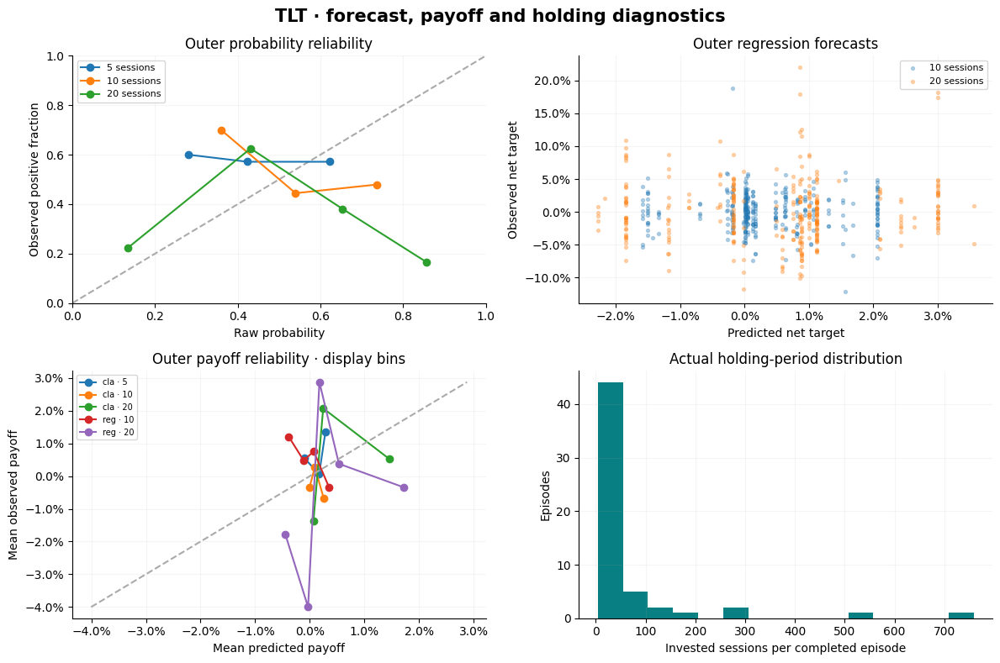

In [100]:
S.forecast_figure('TLT')

### TLT · factors, exposure and benchmark evidence

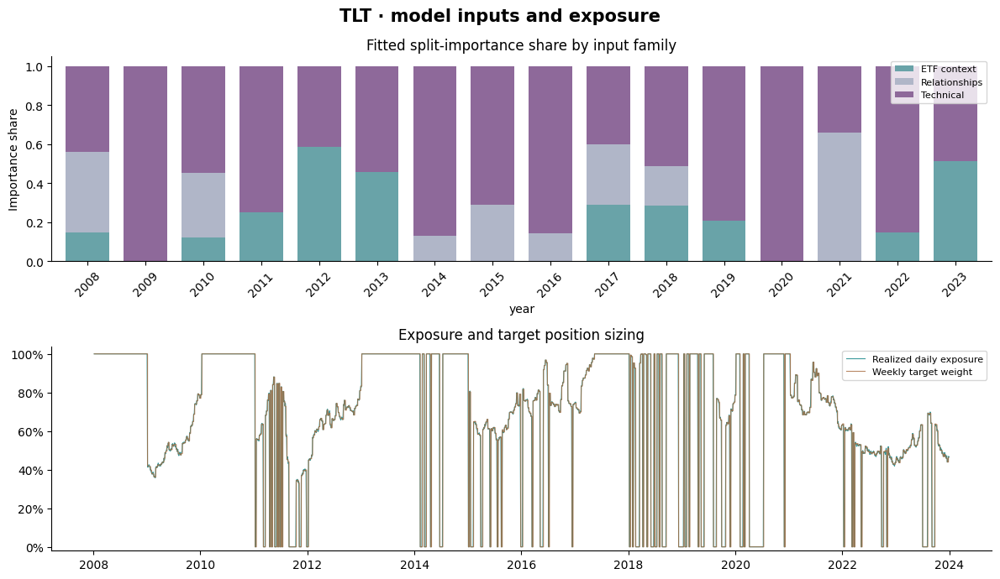

In [101]:
S.factor_figure('TLT')

In [102]:
display(HTML(S.benchmark_tables('TLT')))

## TIP · equity, trades and model settings

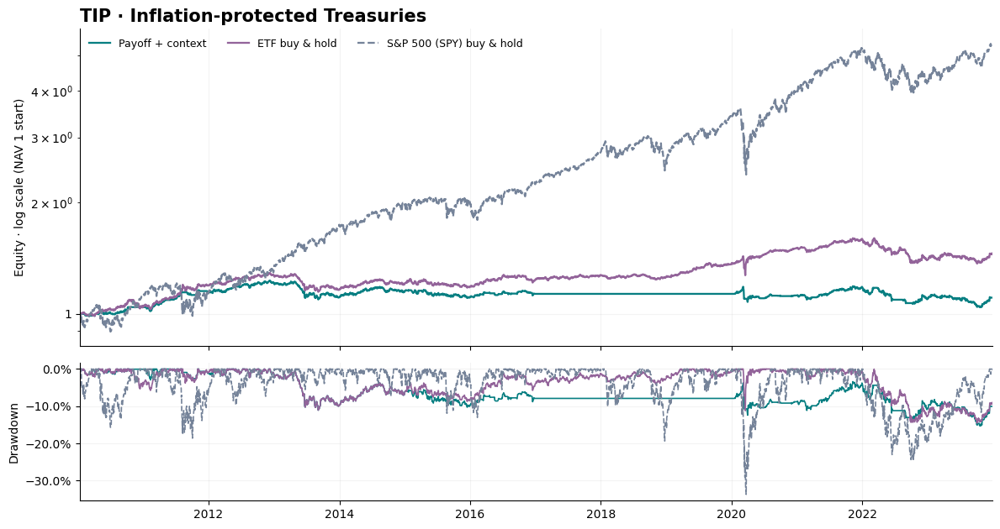

In [103]:
R.plot('TIP')

In [104]:
display(HTML(R.details('TIP')))

### TIP · risk, return distribution and time stability

In [105]:
display(HTML(S.risk_tables('TIP')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2010-01-11,2010-01-11,2010-01-11
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,3517,3517,3517
,days,3517,3517,3517
,calendar days,5101,5101,5101
,elapsed calendar days,5100,5100,5100
,annualization years 252,13.956,13.956,13.956
,net return,0.106,0.451,4.367
,annualized return,0.007,0.027,0.128
,annualized mean return,0.008,0.028,0.136


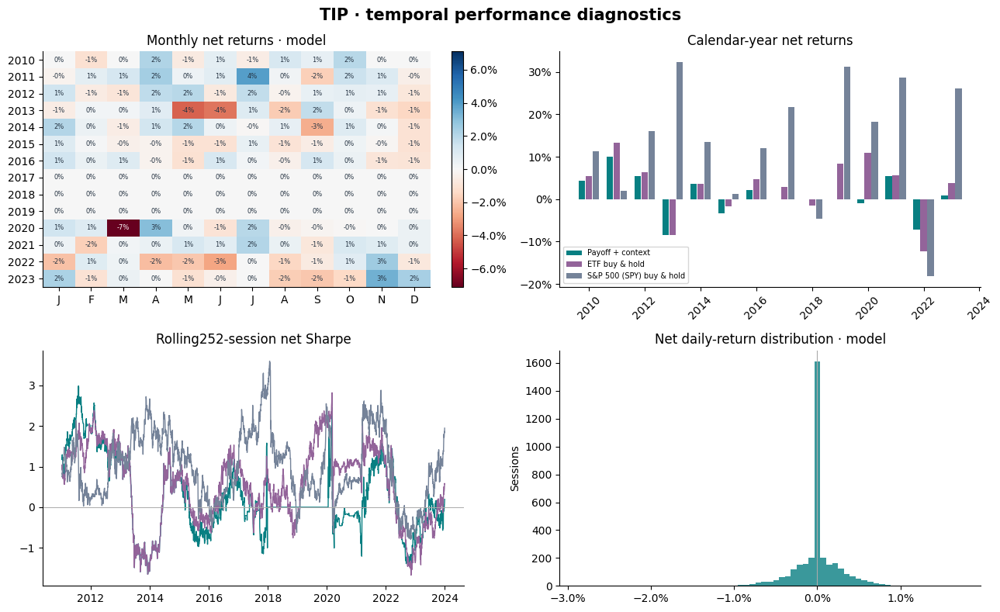

In [106]:
S.temporal_figure('TIP')

In [107]:
display(HTML(S.temporal_tables('TIP')))

### TIP · forecasts, payoff reliability and actual weekly intervals

In [108]:
display(HTML(S.forecast_tables('TIP')))

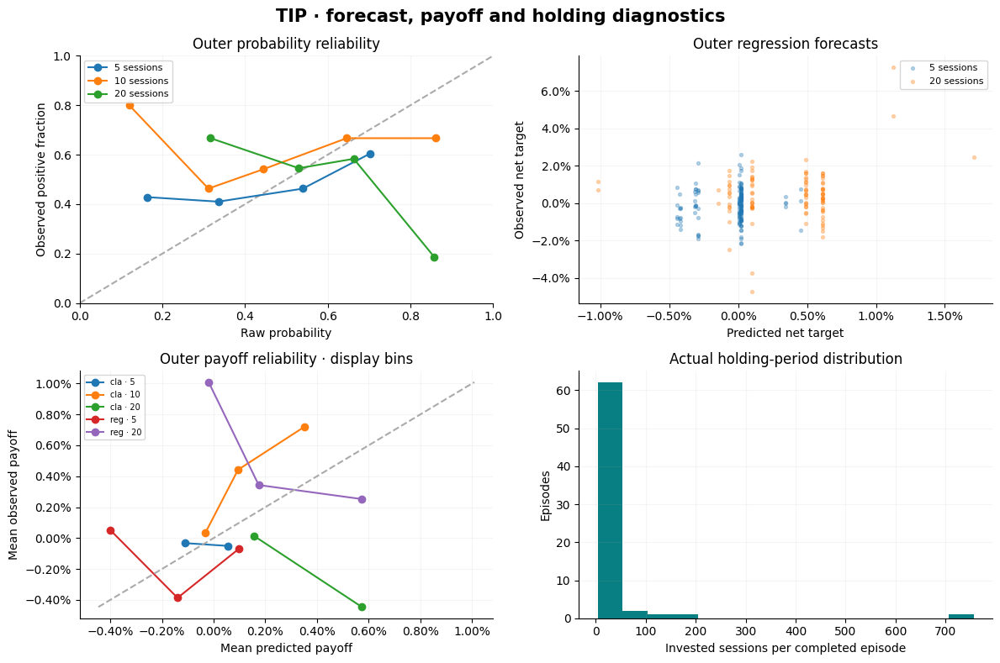

In [109]:
S.forecast_figure('TIP')

### TIP · factors, exposure and benchmark evidence

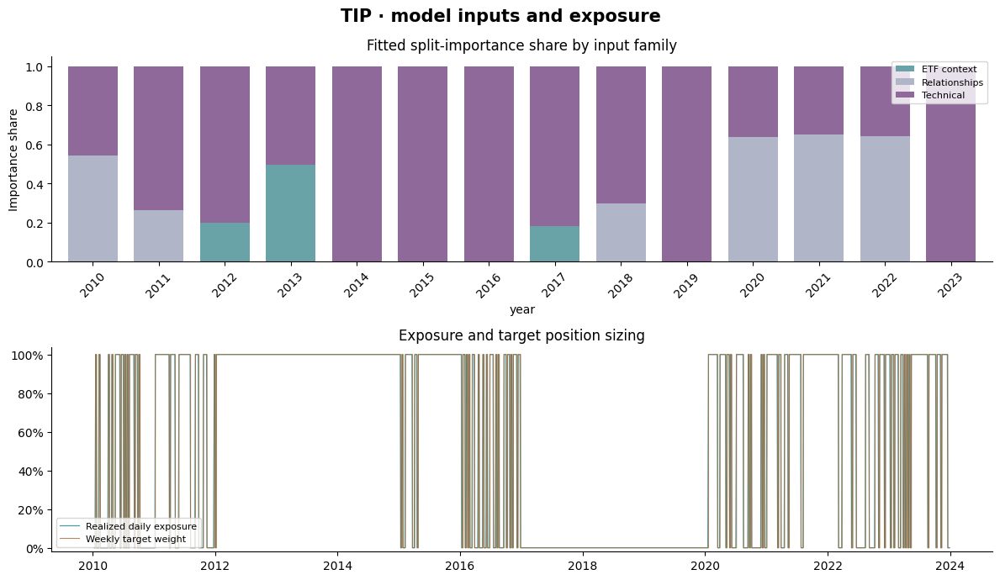

In [110]:
S.factor_figure('TIP')

In [111]:
display(HTML(S.benchmark_tables('TIP')))

## GLD · equity, trades and model settings

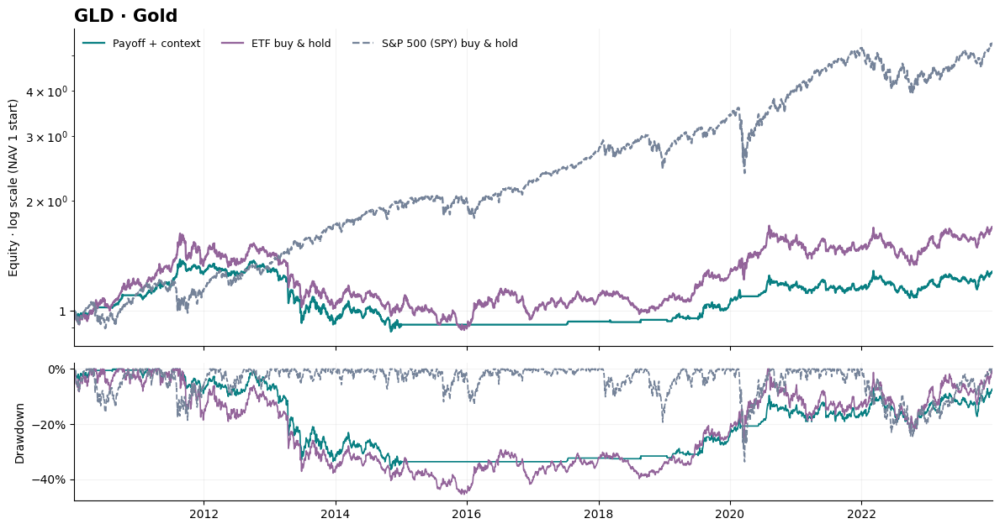

In [112]:
R.plot('GLD')

In [113]:
display(HTML(R.details('GLD')))

### GLD · risk, return distribution and time stability

In [114]:
display(HTML(S.risk_tables('GLD')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2010-01-11,2010-01-11,2010-01-11
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,3517,3517,3517
,days,3517,3517,3517
,calendar days,5101,5101,5101
,elapsed calendar days,5100,5100,5100
,annualization years 252,13.956,13.956,13.956
,net return,0.275,0.685,4.367
,annualized return,0.018,0.038,0.128
,annualized mean return,0.023,0.049,0.136


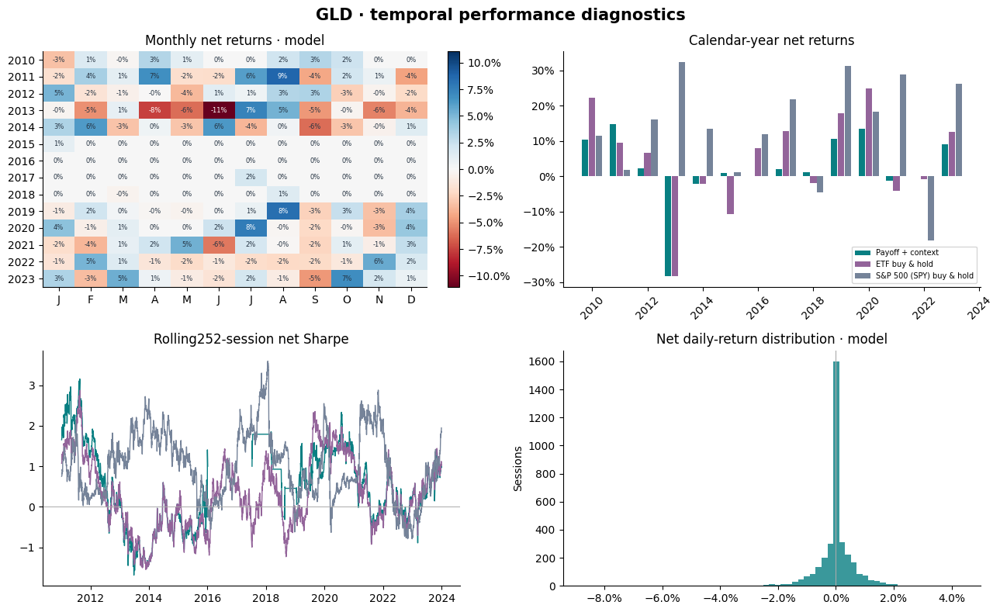

In [115]:
S.temporal_figure('GLD')

In [116]:
display(HTML(S.temporal_tables('GLD')))

### GLD · forecasts, payoff reliability and actual weekly intervals

In [117]:
display(HTML(S.forecast_tables('GLD')))

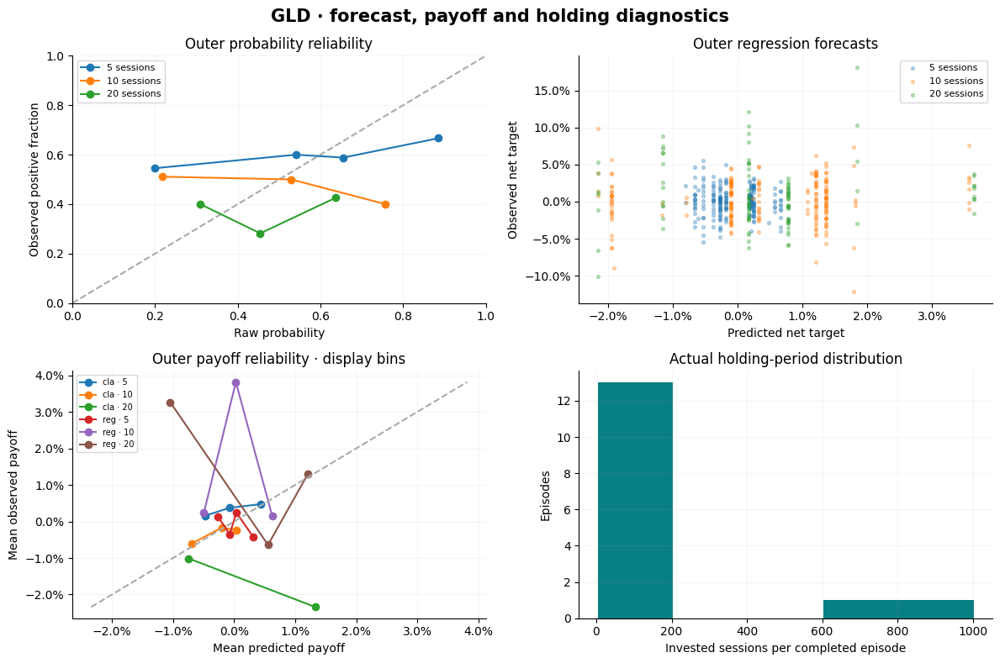

In [118]:
S.forecast_figure('GLD')

### GLD · factors, exposure and benchmark evidence

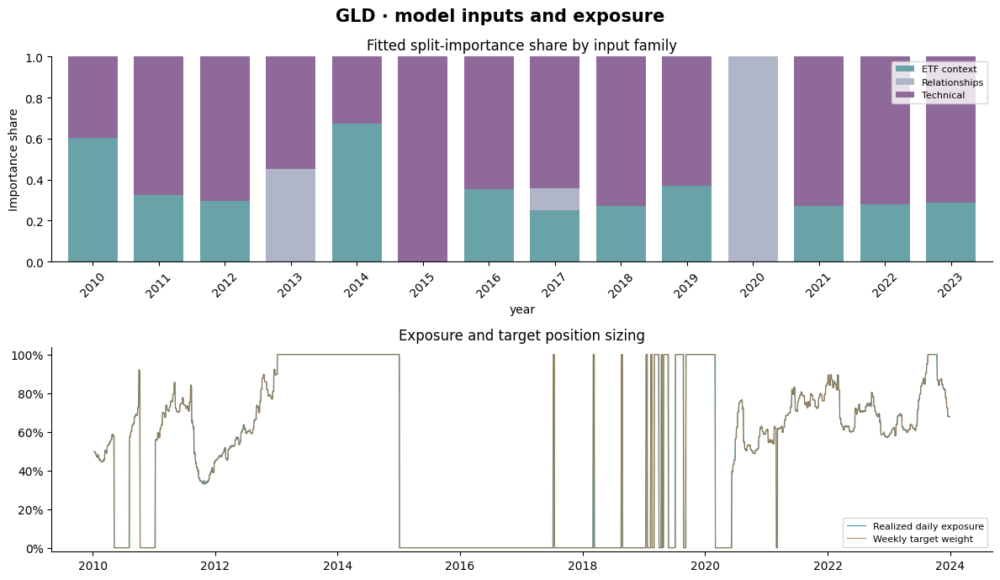

In [119]:
S.factor_figure('GLD')

In [120]:
display(HTML(S.benchmark_tables('GLD')))

## DBC · equity, trades and model settings

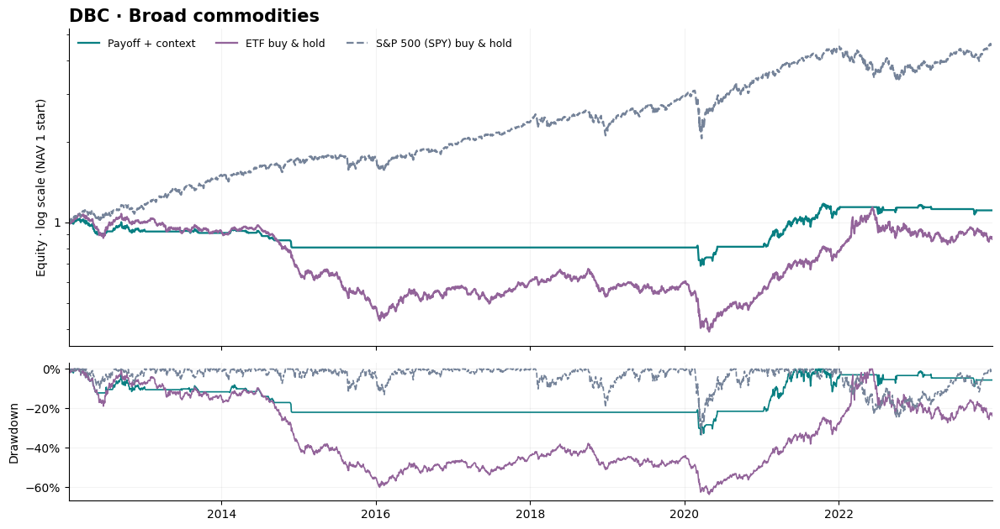

In [121]:
R.plot('DBC')

In [122]:
display(HTML(R.details('DBC')))

### DBC · risk, return distribution and time stability

In [123]:
display(HTML(S.risk_tables('DBC')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2012-01-09,2012-01-09,2012-01-09
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,3014,3014,3014
,days,3014,3014,3014
,calendar days,4373,4373,4373
,elapsed calendar days,4372,4372,4372
,annualization years 252,11.960,11.960,11.960
,net return,0.108,-0.134,3.635
,annualized return,0.009,-0.012,0.137
,annualized mean return,0.012,0.002,0.142


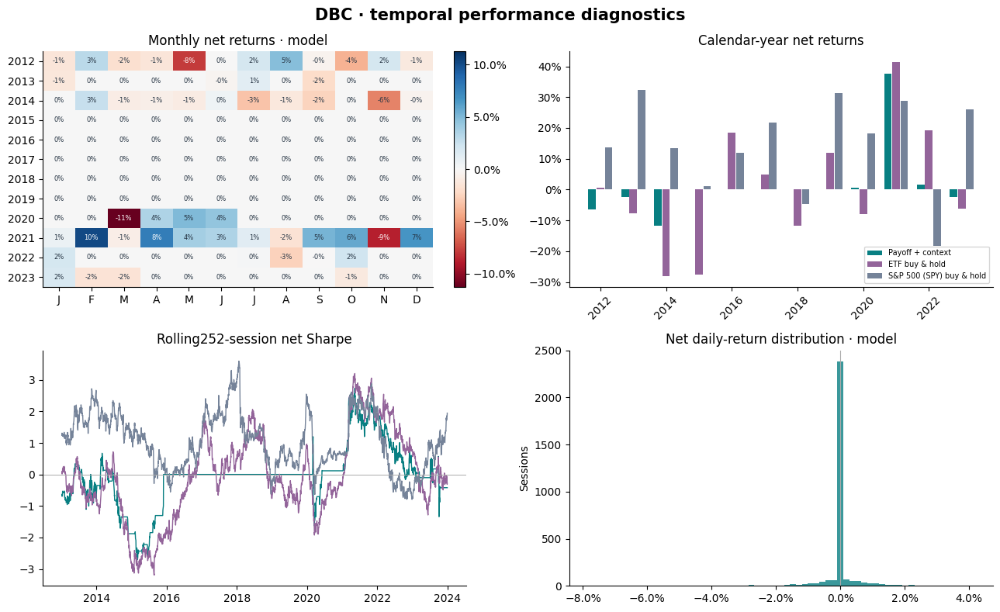

In [124]:
S.temporal_figure('DBC')

In [125]:
display(HTML(S.temporal_tables('DBC')))

### DBC · forecasts, payoff reliability and actual weekly intervals

In [126]:
display(HTML(S.forecast_tables('DBC')))

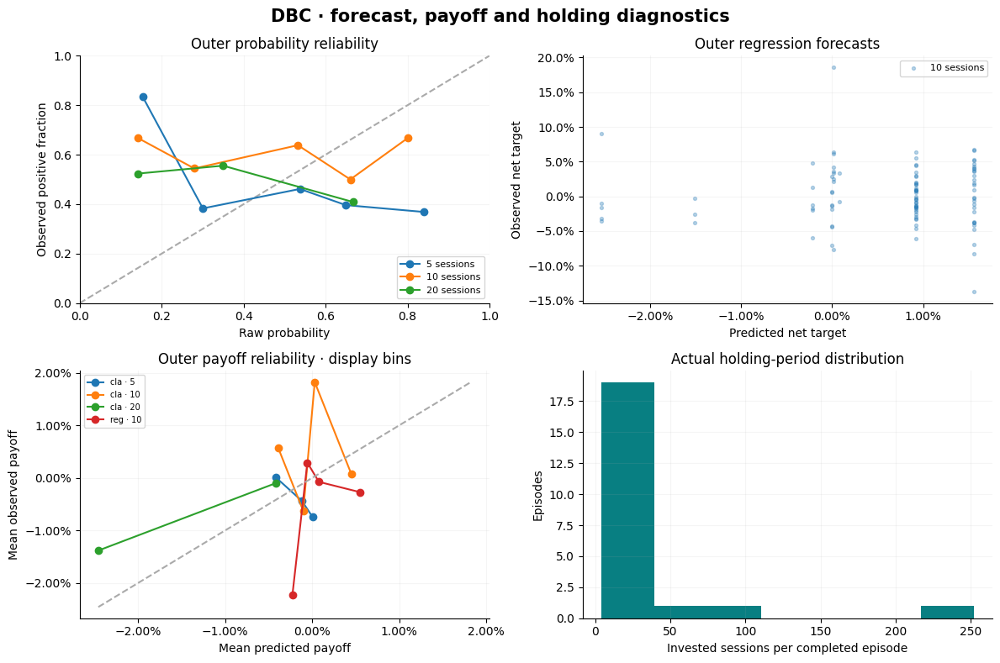

In [127]:
S.forecast_figure('DBC')

### DBC · factors, exposure and benchmark evidence

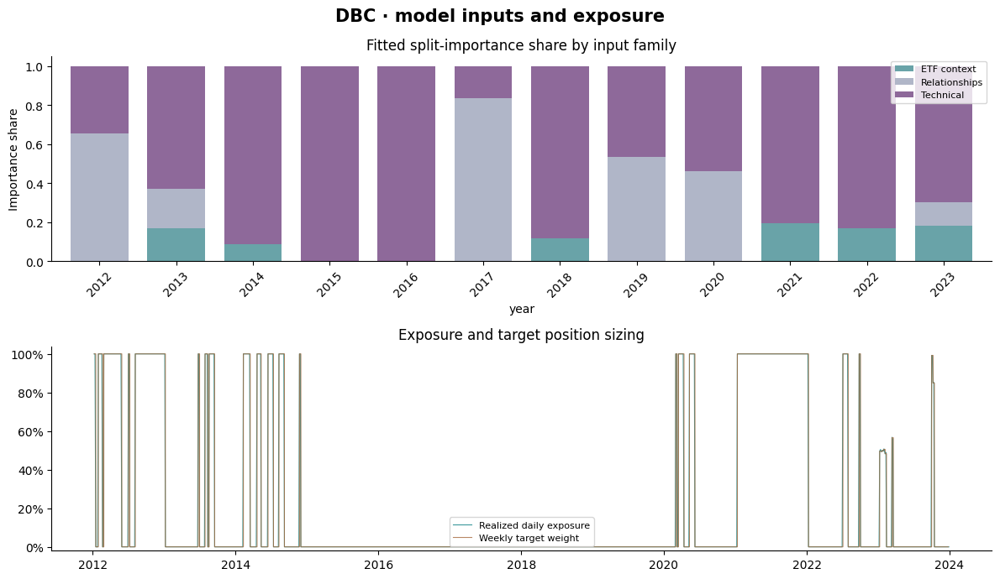

In [128]:
S.factor_figure('DBC')

In [129]:
display(HTML(S.benchmark_tables('DBC')))

## VNQ · equity, trades and model settings

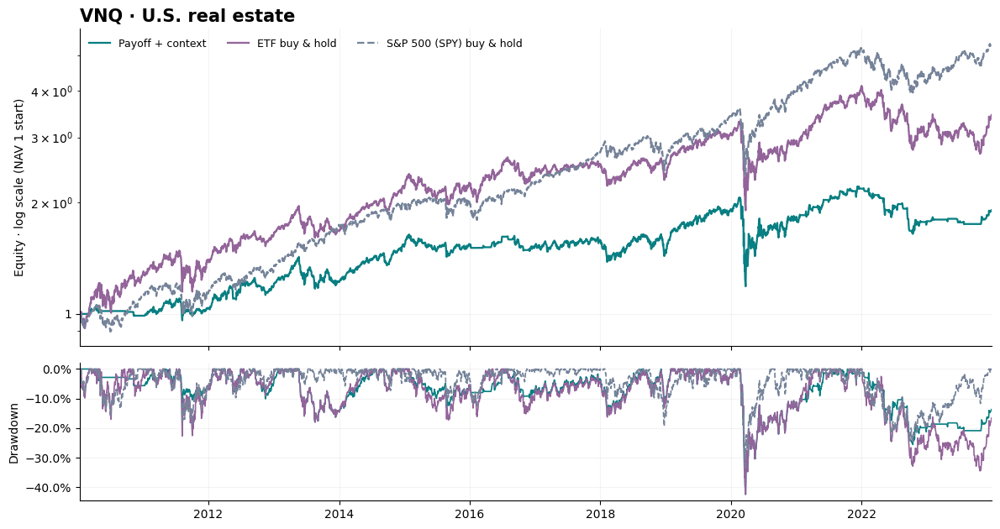

In [130]:
R.plot('VNQ')

In [131]:
display(HTML(R.details('VNQ')))

### VNQ · risk, return distribution and time stability

In [132]:
display(HTML(S.risk_tables('VNQ')))

Account,Measure,Payoff + context,ETF buy & hold,S&P 500 (SPY) buy & hold
,start,2010-01-11,2010-01-11,2010-01-11
,end,2023-12-29,2023-12-29,2023-12-29
,sessions,3517,3517,3517
,days,3517,3517,3517
,calendar days,5101,5101,5101
,elapsed calendar days,5100,5100,5100
,annualization years 252,13.956,13.956,13.956
,net return,0.899,2.407,4.367
,annualized return,0.047,0.092,0.128
,annualized mean return,0.059,0.110,0.136


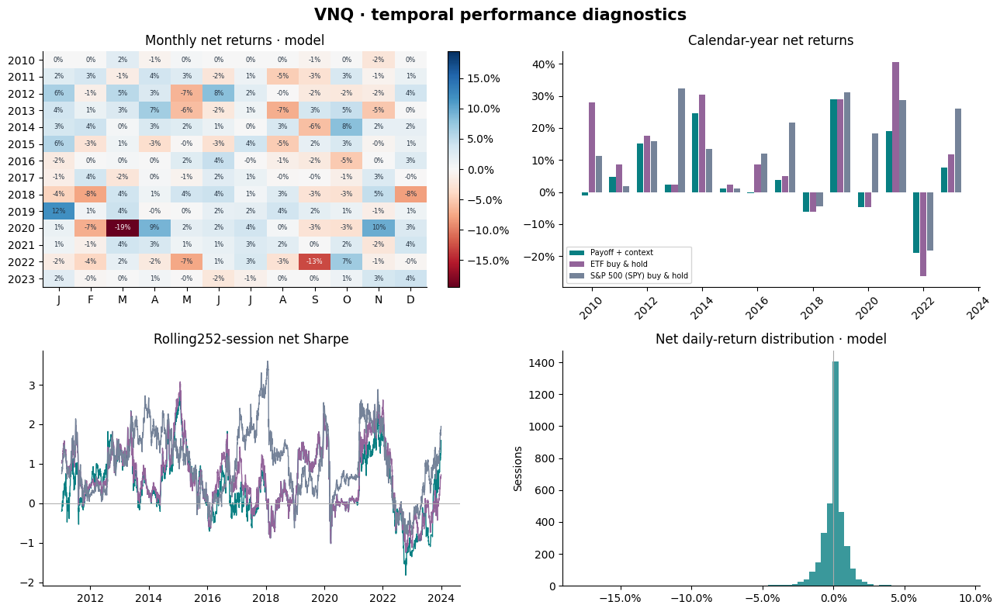

In [133]:
S.temporal_figure('VNQ')

In [134]:
display(HTML(S.temporal_tables('VNQ')))

### VNQ · forecasts, payoff reliability and actual weekly intervals

In [135]:
display(HTML(S.forecast_tables('VNQ')))

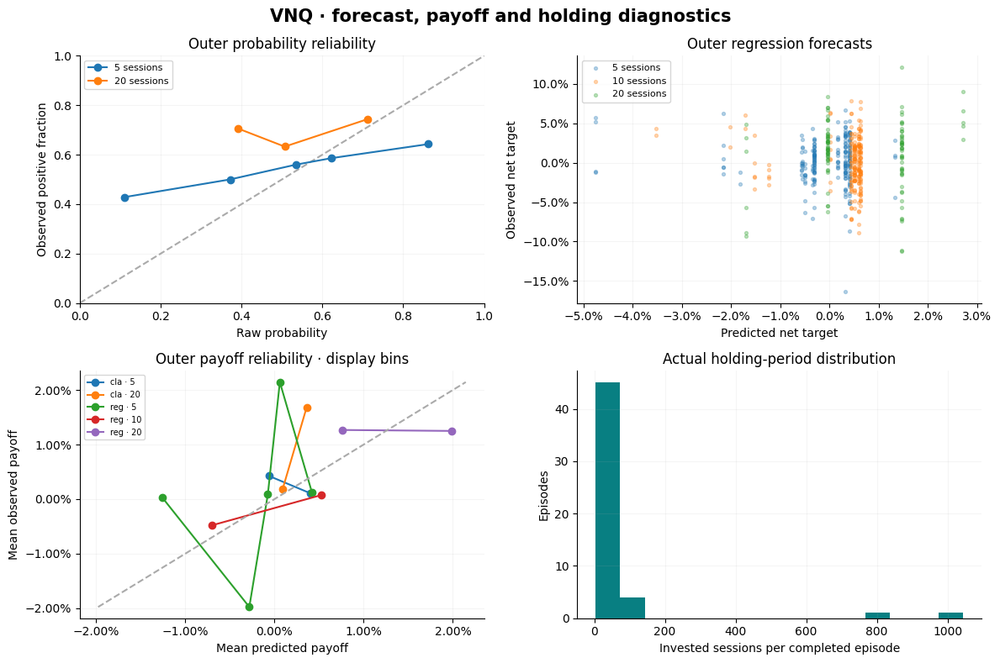

In [136]:
S.forecast_figure('VNQ')

### VNQ · factors, exposure and benchmark evidence

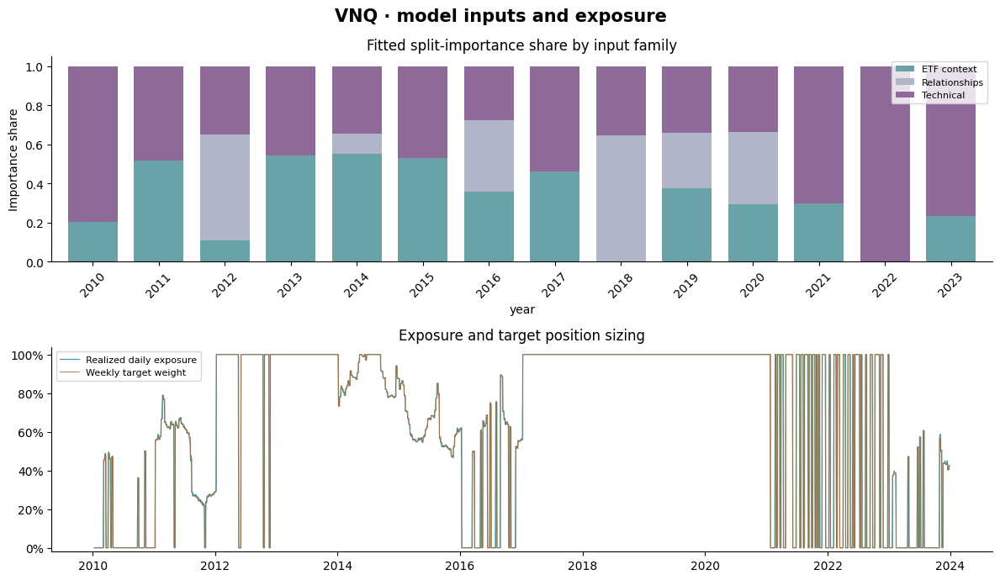

In [137]:
S.factor_figure('VNQ')

In [138]:
display(HTML(S.benchmark_tables('VNQ')))

## Literature, limitations and next research questions

This is a statistical reporting extension of the same v3.1 model. It does not add strategy variants or use the reserved period. The parent study's 225-comparison multiplicity history remains relevant even when only the combined procedure is displayed.

Priorities are calibration support and stability, the effect of turnover and exposure, simple trend/passive-volatility controls, and qualified direct economic factors. Macro and FinBERT remain outside the fitted model until historical data availability is qualified. Vendor-adjusted synthetic total returns, XLF's 2016 distribution, zero cash yield and constant fees remain practical limitations.

In [139]:
display(HTML(S.literature_tables()))
display(HTML(R.verification()))

Paper,Evidence,Limits for this model
Volatility-Managed Portfolios (2017),Prior realized variance inversely scales monthly factor exposure. Studied factors show improved risk-adjusted performance because their expected returns do not rise proportionately with volatility.,"Inverse variance differs from this system's inverse-volatility cap. Factor portfolios, leverage, cash and scaling conventions differ from an unlevered weekly single-ETF account."
Time Series Momentum (2012),"Across 58 futures and forwards, own past returns exhibit continuation over roughly one to twelve months. The strategy combines return signs with lagged volatility scaling.","Evidence uses diversified, often leveraged long/short futures. ETF long/cash removes shorts, changes carry and costs, and may weaken the result."
â€¦ and the Cross-Section of Expected Returns (2016),A large literature of tested factors requires stronger significance standards than isolated tests; the authors derive thresholds reflecting extensive factor searches.,"Their often-cited t-statistic hurdle is not a universal cutoff for weekly ETF timing. Correlation, hidden trials and overlapping labels matter here."
"The Deflated Sharpe Ratio: Correcting for Selection Bias, Backtest Overfitting, and Non-Normality (2014)","DSR adjusts a selected Sharpe statistic for multiple searching, sample length and non-normal returns, using information about the distribution and dependence of trials.","Unknown prior searches, serial dependence and uncertain effective trial counts make a mechanical DSR confidence claim unreliable; raw configuration count is not independence."
The Probability of Backtest Overfitting (2017),The authors propose combinatorially symmetric cross-validation to estimate how often an in-sample winner ranks below the median on the complementary selection subset.,"CSCV is an overfitting diagnostic, not chronological deployment validation. Partitioning dependent returns and omitting unsuccessful trials can distort its interpretation."
Backtesting Strategies Based on Multiple Signals (2015),Selecting and signing multiple signals can generate severe overfitting even from random inputs. Searching signal combinations compounds ordinary multiple-testing bias.,"Cross-sectional stock-selection experiments do not numerically calibrate ETF timing bias. The warning nevertheless applies to feature subsets, signs, thresholds and regime combinations."
Empirical Asset Pricing via Machine Learning (2020),"Nonlinear interactions help tree and neural models in a large stock panel; momentum, liquidity and volatility remain influential. Tuning and testing use separated chronological samples.",Thousands of stocks and decades of monthly panel observations differ sharply from one ETF's weekly samples; this is not evidence that larger networks improve this project.
A Comprehensive Look at the Empirical Performance of Equity Premium Prediction (2008),"Many proposed aggregate equity-premium predictors performed poorly out of sample and exhibited unstable relationships, undermining the market-timing benefit implied by in-sample fits.",Aggregate equity-premium regressions do not settle every ETF or nonlinear method. Their historical-average benchmark remains a useful low-complexity hurdle.
Predicting Excess Stock Returns Out of Sample: Can Anything Beat the Historical Average? (2008),"Economically motivated restrictions on coefficient signs and forecasts allow some predictive regressions to improve upon historical-average forecasts, although explanatory gains remain small.","Equity-premium sign restrictions need not hold for Treasury, commodity or sector ETF returns. The paper does not validate this project's specific calibration or shrinkage rule."
On the Performance of Volatility-Managed Portfolios (2020),"Across 103 equity strategies, volatility-managed portfolios do not systematically win direct comparisons. Implementable out-of-sample combinations often disappoint because the spanning relations are unst